In [90]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("C:/Users/jsmvk/Desktop/SGH/Praca magisterska/south+german+credit+update/SouthGermanCredit.asc", sep = " ", engine = "python")

[Text(0, 0, '300'), Text(0, 0, '700')]

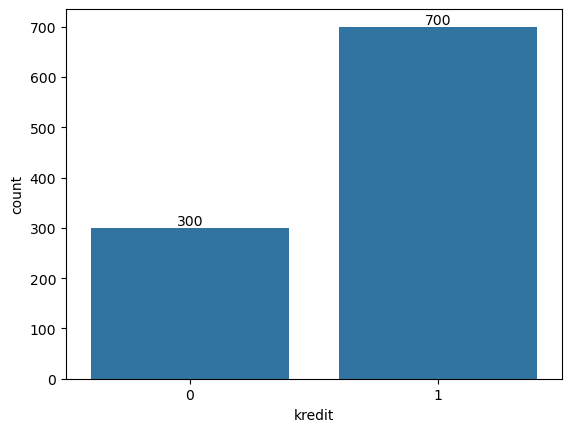

In [91]:
ax = sns.countplot(data = df, x = 'kredit')
ax.bar_label(ax.containers[0])

In [92]:
from sdv.single_table import GaussianCopulaSynthesizer
from sdv.metadata import Metadata

In [93]:
#metadata = Metadata.detect_from_dataframe(df)

#synthesizer = GaussianCopulaSynthesizer(metadata)
#synthesizer.fit(df[df["kredit"] == 0])

#synthetic_data_0 = synthesizer.sample(num_rows = 400)
#synthetic_data_0.to_excel('C:/Users/jsmvk/Desktop/SGH/Praca magisterska/synthetic_data.xlsx', index=False)

In [94]:
synthetic_data_0 = pd.read_excel("C:/Users/jsmvk/Desktop/SGH/Praca magisterska/synthetic_data.xlsx", engine = 'openpyxl')

In [95]:
len(synthetic_data_0[synthetic_data_0["kredit"] == 0])

400

In [96]:
df = pd.concat([synthetic_data_0, df], axis = 0)

In [97]:
df = df.sample(frac = 1).reset_index(drop = True)

In [98]:
mapping_colnames = {
    
    "laufkont":"stan_konta",
    "laufzeit":"czas_zapadalności_kredytu",
    "moral":"historia_kredytowa",
    "verw":"cel_kredytu",
    "hoehe":"wielkość_kredytu",
    "sparkont":"oszczędności",
    "beszeit":"czas_zatrudnienia",
    "rate":"wysokość_raty_kredytu",
    "famges":"status_matrymonialny",
    "buerge":"inni_kredytobiorcy",
    "wohnzeit":"miejsce_zamieszkania",
    "verm":"najdroższa_własność",
    "alter":"wiek",
    "weitkred":"inne_kredyty",
    "wohn":"sposób_opłaty_mieszkania",
    "bishkred":"liczba_kredytów_w_historii",
    "beruf":"praca",
    "pers":"liczba_osób_na_utrzymaniu",
    "telef":"telefon",
    "gastarb":"cudzoziemiec",
    "kredit":"ryzyko_kredytowe"
    
}

In [99]:
df.rename(columns = mapping_colnames, inplace = True)

In [100]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   stan_konta                  1400 non-null   int64
 1   czas_zapadalności_kredytu   1400 non-null   int64
 2   historia_kredytowa          1400 non-null   int64
 3   cel_kredytu                 1400 non-null   int64
 4   wielkość_kredytu            1400 non-null   int64
 5   oszczędności                1400 non-null   int64
 6   czas_zatrudnienia           1400 non-null   int64
 7   wysokość_raty_kredytu       1400 non-null   int64
 8   status_matrymonialny        1400 non-null   int64
 9   inni_kredytobiorcy          1400 non-null   int64
 10  miejsce_zamieszkania        1400 non-null   int64
 11  najdroższa_własność         1400 non-null   int64
 12  wiek                        1400 non-null   int64
 13  inne_kredyty                1400 non-null   int64
 14  sposób_opłaty_miesz

In [101]:
df['cel_kredytu'].unique()

array([ 3,  2,  0,  1,  5,  9,  4,  6, 10,  8])

In [102]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   stan_konta                  1400 non-null   int64
 1   czas_zapadalności_kredytu   1400 non-null   int64
 2   historia_kredytowa          1400 non-null   int64
 3   cel_kredytu                 1400 non-null   int64
 4   wielkość_kredytu            1400 non-null   int64
 5   oszczędności                1400 non-null   int64
 6   czas_zatrudnienia           1400 non-null   int64
 7   wysokość_raty_kredytu       1400 non-null   int64
 8   status_matrymonialny        1400 non-null   int64
 9   inni_kredytobiorcy          1400 non-null   int64
 10  miejsce_zamieszkania        1400 non-null   int64
 11  najdroższa_własność         1400 non-null   int64
 12  wiek                        1400 non-null   int64
 13  inne_kredyty                1400 non-null   int64
 14  sposób_opłaty_miesz

In [103]:
#mapping_colnames = dict(np.array(credit_approval.variables[["name", "description"]]))

In [104]:
#df.rename(columns = mapping_colnames, inplace = True)
#df.rename(columns = {'1 = Good, 0 = Bad' : 'class'}, inplace = True)

In [105]:
#df.info()

In [106]:
df.describe(exclude = "object")

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,najdroższa_własność,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe
count,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,...,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000,1400.000000
mean,2.397143,22.181429,2.427857,2.903571,3479.517857,1.992143,3.353571,3.005000,2.652143,1.135000,...,2.438571,34.568571,2.634286,1.923571,1.393571,2.908571,1.854286,1.379286,1.970000,0.500000
std,1.244628,12.411399,1.086901,2.899062,2999.275355,1.526257,1.212274,1.120019,0.726105,0.453314,...,1.050109,11.501606,0.735476,0.561336,0.578469,0.663722,0.352946,0.485383,0.170648,0.500179
min,1.000000,4.000000,0.000000,0.000000,250.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,19.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,1.000000,12.000000,2.000000,0.000000,1364.000000,1.000000,3.000000,2.000000,2.000000,1.000000,...,1.000000,26.000000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.000000
50%,2.000000,19.000000,2.000000,2.000000,2440.000000,1.000000,3.000000,3.000000,3.000000,1.000000,...,3.000000,32.000000,3.000000,2.000000,1.000000,3.000000,2.000000,1.000000,2.000000,0.500000
75%,4.000000,29.000000,3.250000,3.000000,4493.000000,3.000000,4.000000,4.000000,3.000000,1.000000,...,3.000000,40.250000,3.000000,2.000000,2.000000,3.000000,2.000000,2.000000,2.000000,1.000000
max,4.000000,72.000000,4.000000,10.000000,18424.000000,5.000000,5.000000,4.000000,4.000000,3.000000,...,4.000000,75.000000,3.000000,3.000000,4.000000,4.000000,2.000000,2.000000,2.000000,1.000000


In [107]:
def describe_advanced(data):
    
    data = np.asarray(data)
    
    return {
        "max": np.max(data),
        "min": np.min(data),
        "dominanta": stats.mode(data).mode[0],
        "kurtoza": np.round(stats.kurtosis(data), 2),
        "skośność": np.round(stats.skew(data), 2),
        "średnia": np.round(np.mean(data), 2),
        "odchylenie standardowe": np.round(np.std(data), 2),
        "współczynnik zmienności": np.round(np.round(np.std(data), 2) / np.round(np.mean(data), 2), 2)
    }

In [108]:
num_cols = ['czas_zapadalności_kredytu', 'wielkość_kredytu', 'wiek']

In [109]:
cat_cols = []

for i in df.columns:
    if i not in num_cols:
        cat_cols.append(i)

In [110]:
cat_cols.remove("ryzyko_kredytowe")
df[cat_cols] = df[cat_cols].astype("object")

In [111]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   stan_konta                  1400 non-null   object
 1   czas_zapadalności_kredytu   1400 non-null   int64 
 2   historia_kredytowa          1400 non-null   object
 3   cel_kredytu                 1400 non-null   object
 4   wielkość_kredytu            1400 non-null   int64 
 5   oszczędności                1400 non-null   object
 6   czas_zatrudnienia           1400 non-null   object
 7   wysokość_raty_kredytu       1400 non-null   object
 8   status_matrymonialny        1400 non-null   object
 9   inni_kredytobiorcy          1400 non-null   object
 10  miejsce_zamieszkania        1400 non-null   object
 11  najdroższa_własność         1400 non-null   object
 12  wiek                        1400 non-null   int64 
 13  inne_kredyty                1400 non-null   object
 14  spo

[Text(0, 0, '700'), Text(0, 0, '700')]

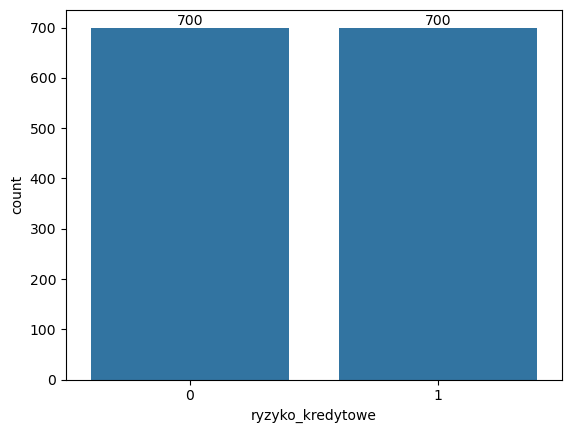

In [112]:
ax = sns.countplot(data = df, x = 'ryzyko_kredytowe')
ax.bar_label(ax.containers[0])

In [113]:
output = []

for i in num_cols:
    descriptive_statistics = describe_advanced(df[[i]])
    descriptive_statistics['column'] = i
    output.append(descriptive_statistics)

descriptive_stats = pd.DataFrame(output)
descriptive_stats.set_index("column", inplace = True)
descriptive_stats.index.name = None

In [114]:
descriptive_stats

,max,min,dominanta,kurtoza,skośność,średnia,odchylenie standardowe,współczynnik zmienności
czas_zapadalności_kredytu,72,4,24,[0.67],[1.01],22.18,12.41,0.56
wielkość_kredytu,18424,250,458,[3.1],[1.73],3479.52,2998.20,0.86
wiek,75,19,23,[0.65],[1.05],34.57,11.50,0.33


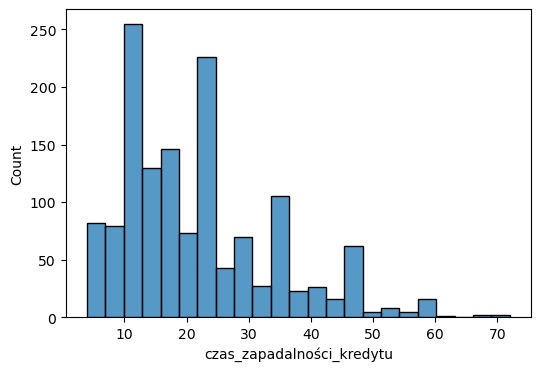

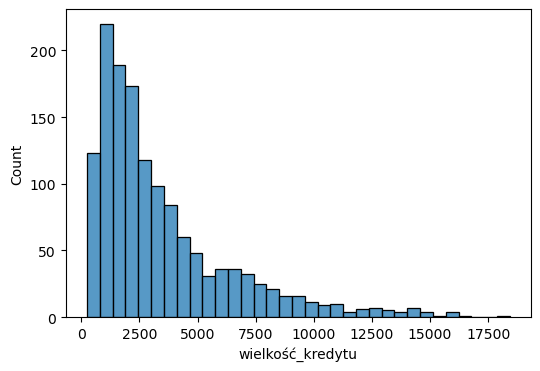

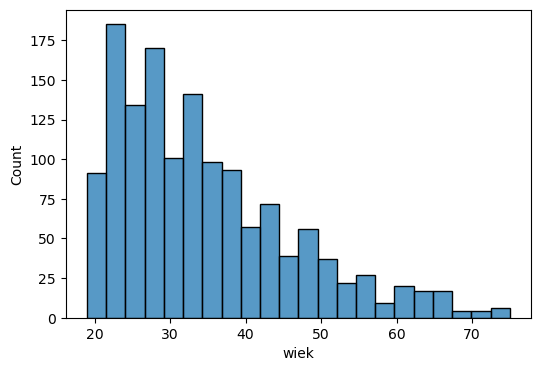

In [115]:
for i in num_cols:
     plt.figure(figsize=(6, 4))
     histograms = sns.histplot(df[i])
     plt.show()

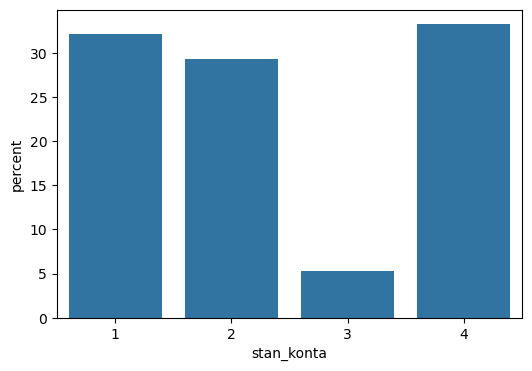

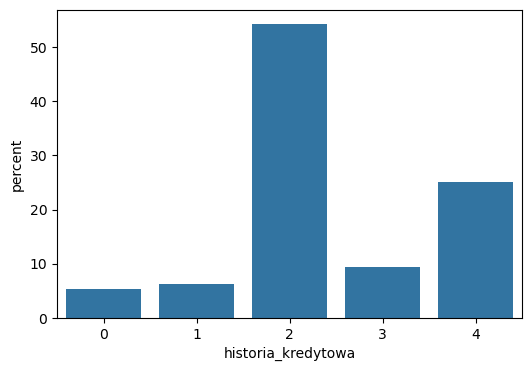

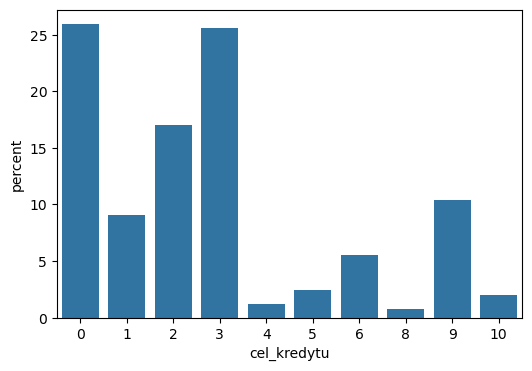

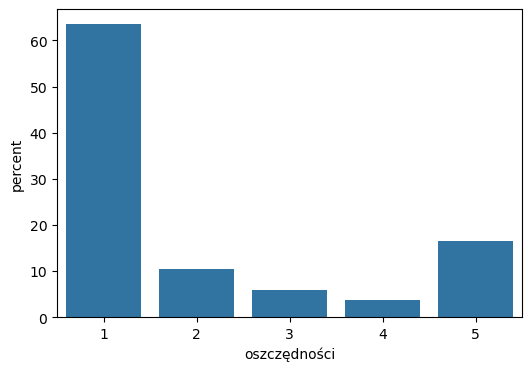

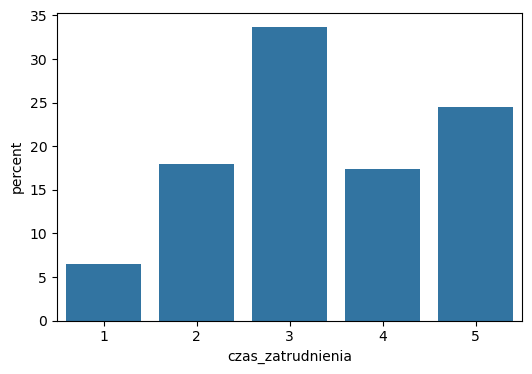

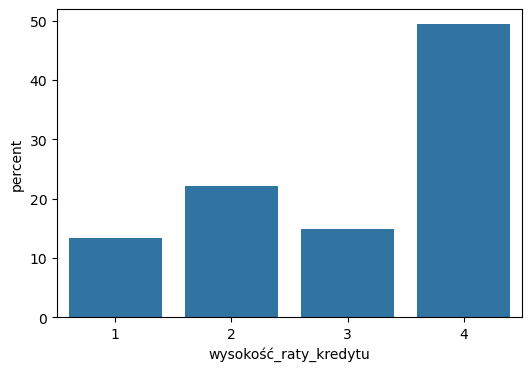

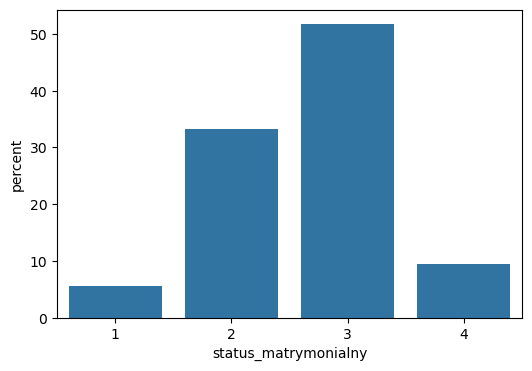

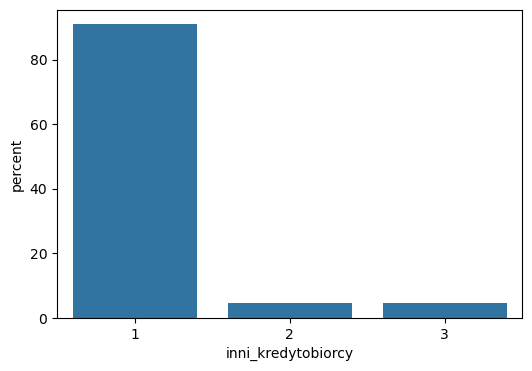

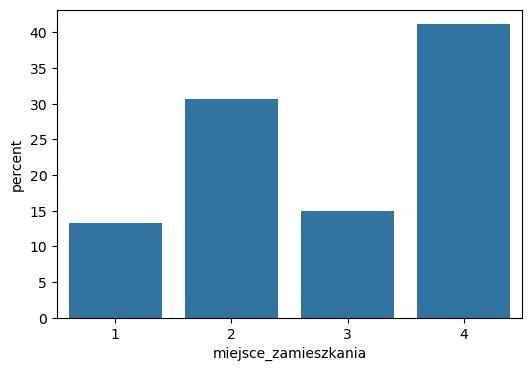

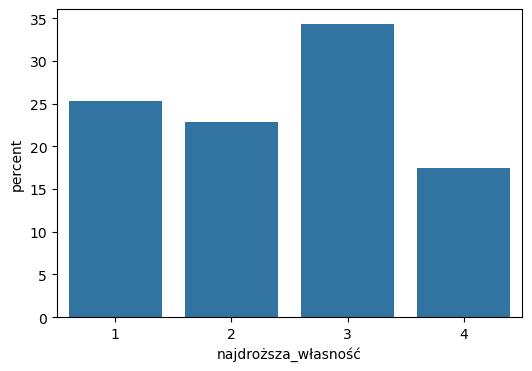

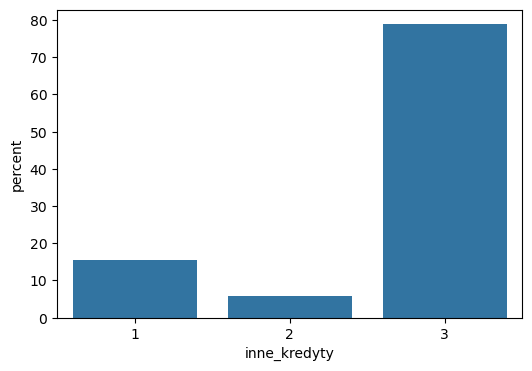

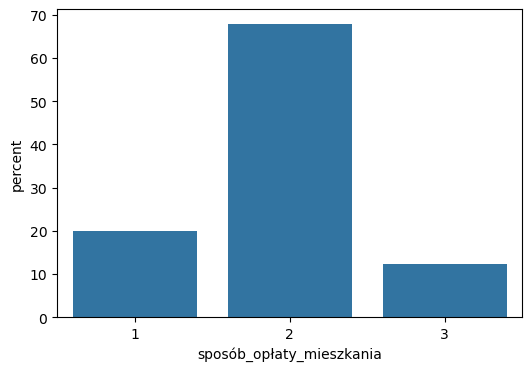

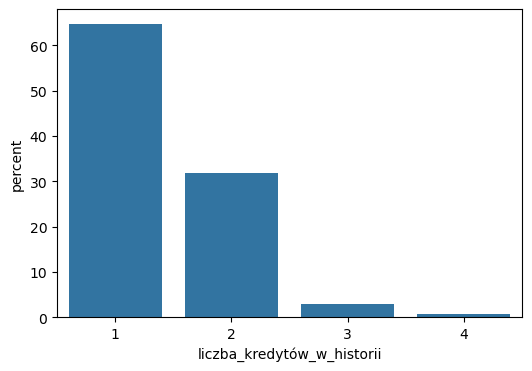

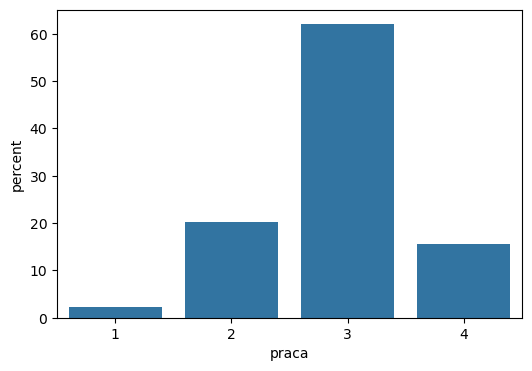

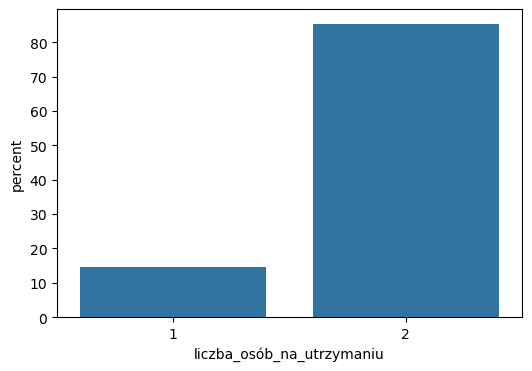

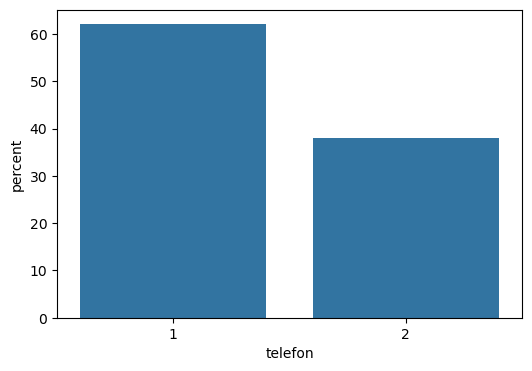

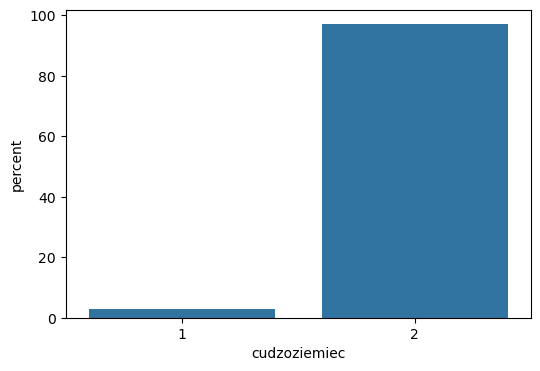

In [116]:
for i in cat_cols:
     plt.figure(figsize=(6, 4))
     countplots = sns.countplot(x = df[i], stat = "percent")
     plt.show()

In [117]:
scores = []

for i in cat_cols:
        name = i
        percent = df[i].value_counts() / len(df) * 100
        
        for category, percent in percent.items():
            scores.append({
                "Variable" : i,
                "Category": category,
                "Percent": percent
            })

In [118]:
scores = pd.DataFrame(scores)

In [119]:
scores.set_index("Variable", inplace = True)

In [120]:
scores.sort_values(by = ["Variable", "Category"], inplace = True)

In [121]:
print(scores.to_string())

                            Category    Percent
Variable                                       
cel_kredytu                        0  25.928571
cel_kredytu                        1   9.071429
cel_kredytu                        2  17.000000
cel_kredytu                        3  25.571429
cel_kredytu                        4   1.214286
cel_kredytu                        5   2.428571
cel_kredytu                        6   5.571429
cel_kredytu                        8   0.785714
cel_kredytu                        9  10.428571
cel_kredytu                       10   2.000000
cudzoziemiec                       1   3.000000
cudzoziemiec                       2  97.000000
czas_zatrudnienia                  1   6.500000
czas_zatrudnienia                  2  18.000000
czas_zatrudnienia                  3  33.642857
czas_zatrudnienia                  4  17.357143
czas_zatrudnienia                  5  24.500000
historia_kredytowa                 0   5.214286
historia_kredytowa                 1   6

In [122]:
scores["Percent"].sum()

np.float64(1699.9999999999998)

<Axes: >

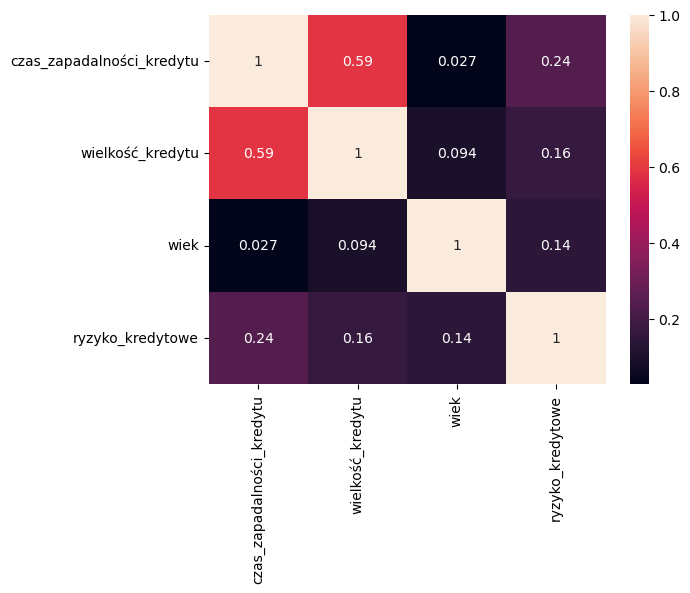

In [123]:
sns.heatmap(df.corr(numeric_only = True).abs(), annot = True)

In [124]:
#df.drop("Duration", axis = 1, inplace = True)

In [125]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1400 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   stan_konta                  1400 non-null   object
 1   czas_zapadalności_kredytu   1400 non-null   int64 
 2   historia_kredytowa          1400 non-null   object
 3   cel_kredytu                 1400 non-null   object
 4   wielkość_kredytu            1400 non-null   int64 
 5   oszczędności                1400 non-null   object
 6   czas_zatrudnienia           1400 non-null   object
 7   wysokość_raty_kredytu       1400 non-null   object
 8   status_matrymonialny        1400 non-null   object
 9   inni_kredytobiorcy          1400 non-null   object
 10  miejsce_zamieszkania        1400 non-null   object
 11  najdroższa_własność         1400 non-null   object
 12  wiek                        1400 non-null   int64 
 13  inne_kredyty                1400 non-null   object
 14  spo

In [126]:
df.head()

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,najdroższa_własność,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe
0,4,22,2,3,2675,3,5,3,3,1,...,3,40,3,2,1,3,2,1,2,1
1,1,18,2,2,2659,4,3,4,3,1,...,3,28,3,2,1,3,2,1,2,1
2,4,24,2,0,5332,1,4,1,1,2,...,2,38,1,2,2,3,2,2,2,0
3,1,21,4,0,1602,1,5,4,4,1,...,3,30,3,2,2,3,2,2,2,1
4,1,25,2,1,4022,1,3,4,4,1,...,4,27,3,2,1,4,2,1,2,0


In [127]:
from sklearn.preprocessing import OneHotEncoder

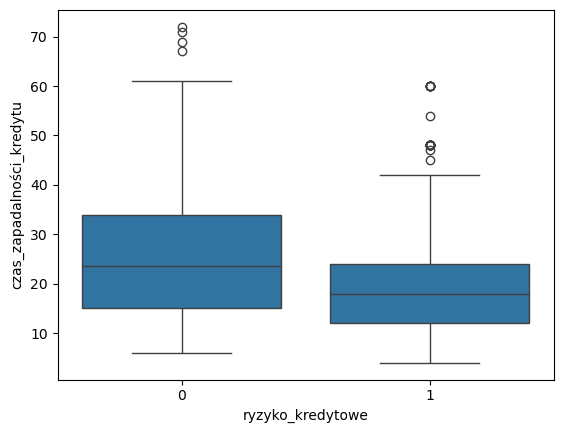

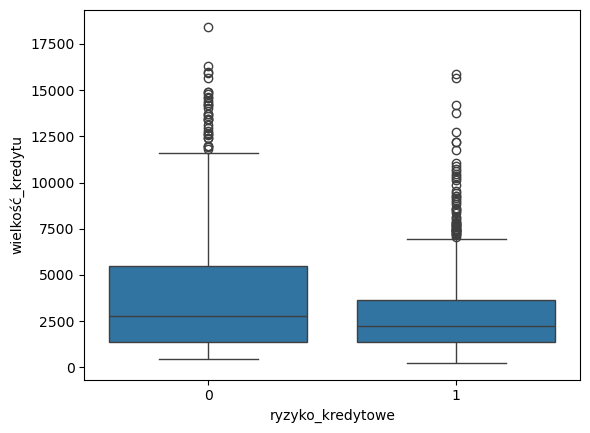

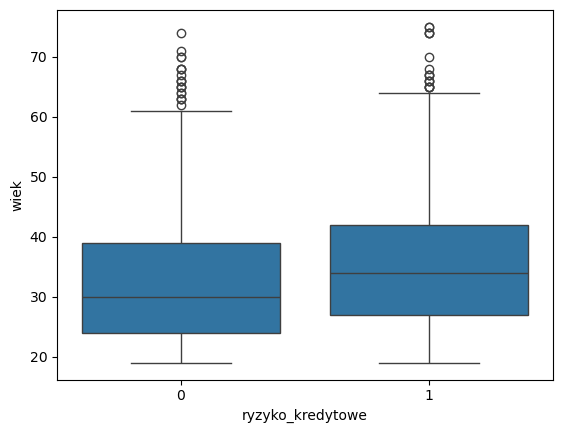

In [128]:
for i in df[num_cols]:
    sns.boxplot(data = df, y = i, x = "ryzyko_kredytowe")
    plt.show()

In [129]:
for i in num_cols:
    q_treshold = df[i].quantile(0.99)
    df = df[df[i] <= q_treshold]

In [130]:
num_cols

['czas_zapadalności_kredytu', 'wielkość_kredytu', 'wiek']

In [131]:
cat_cols

['stan_konta',
 'historia_kredytowa',
 'cel_kredytu',
 'oszczędności',
 'czas_zatrudnienia',
 'wysokość_raty_kredytu',
 'status_matrymonialny',
 'inni_kredytobiorcy',
 'miejsce_zamieszkania',
 'najdroższa_własność',
 'inne_kredyty',
 'sposób_opłaty_mieszkania',
 'liczba_kredytów_w_historii',
 'praca',
 'liczba_osób_na_utrzymaniu',
 'telefon',
 'cudzoziemiec']

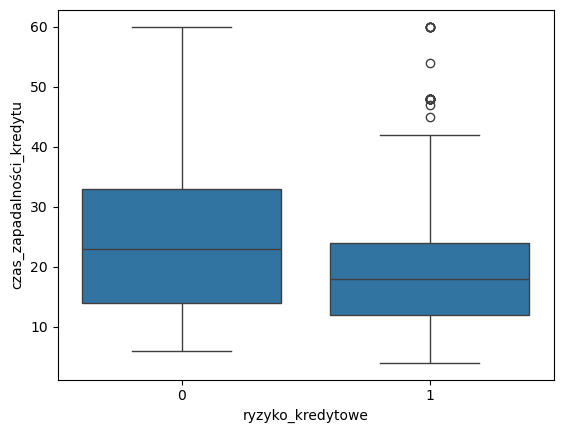

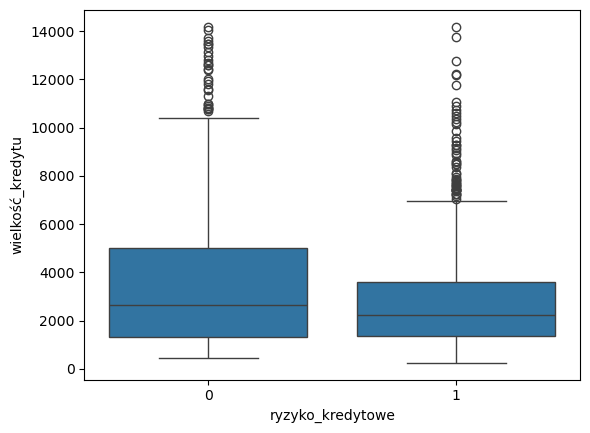

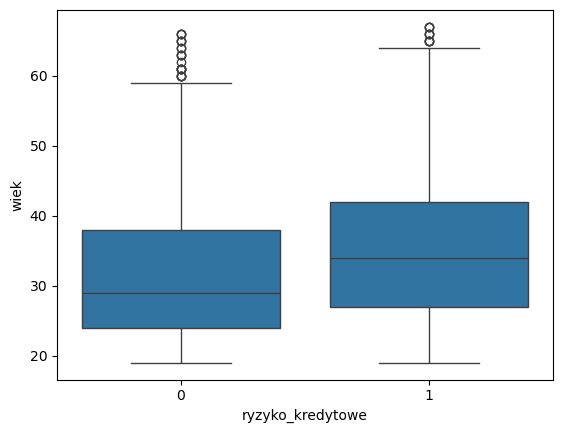

In [132]:
for i in df[num_cols]:
    sns.boxplot(data = df, y = i, x = "ryzyko_kredytowe")
    plt.show()

In [133]:
df.info()

<class 'pandas.DataFrame'>
Index: 1368 entries, 0 to 1399
Data columns (total 21 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   stan_konta                  1368 non-null   object
 1   czas_zapadalności_kredytu   1368 non-null   int64 
 2   historia_kredytowa          1368 non-null   object
 3   cel_kredytu                 1368 non-null   object
 4   wielkość_kredytu            1368 non-null   int64 
 5   oszczędności                1368 non-null   object
 6   czas_zatrudnienia           1368 non-null   object
 7   wysokość_raty_kredytu       1368 non-null   object
 8   status_matrymonialny        1368 non-null   object
 9   inni_kredytobiorcy          1368 non-null   object
 10  miejsce_zamieszkania        1368 non-null   object
 11  najdroższa_własność         1368 non-null   object
 12  wiek                        1368 non-null   int64 
 13  inne_kredyty                1368 non-null   object
 14  sposób_o

In [134]:
sum(df.duplicated())

0

In [135]:
df.reset_index(inplace = True, drop = True)

In [136]:
df.head()

,stan_konta,czas_zapadalności_kredytu,historia_kredytowa,cel_kredytu,wielkość_kredytu,oszczędności,czas_zatrudnienia,wysokość_raty_kredytu,status_matrymonialny,inni_kredytobiorcy,...,najdroższa_własność,wiek,inne_kredyty,sposób_opłaty_mieszkania,liczba_kredytów_w_historii,praca,liczba_osób_na_utrzymaniu,telefon,cudzoziemiec,ryzyko_kredytowe
0,4,22,2,3,2675,3,5,3,3,1,...,3,40,3,2,1,3,2,1,2,1
1,1,18,2,2,2659,4,3,4,3,1,...,3,28,3,2,1,3,2,1,2,1
2,4,24,2,0,5332,1,4,1,1,2,...,2,38,1,2,2,3,2,2,2,0
3,1,21,4,0,1602,1,5,4,4,1,...,3,30,3,2,2,3,2,2,2,1
4,1,25,2,1,4022,1,3,4,4,1,...,4,27,3,2,1,4,2,1,2,0


In [137]:
from sklearn.model_selection import train_test_split

X = df.drop("ryzyko_kredytowe", axis = 1)
y = df["ryzyko_kredytowe"]

[Text(0, 0, '677'), Text(0, 0, '691')]

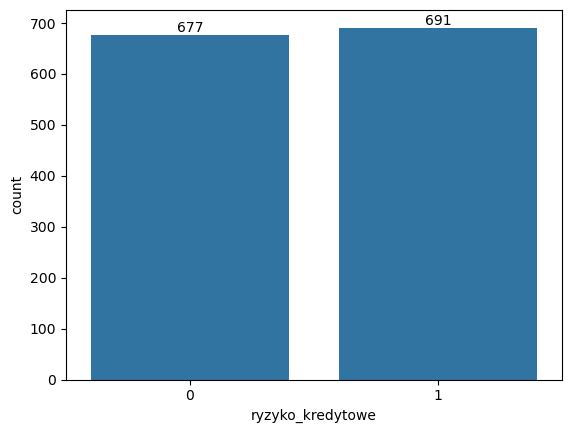

In [138]:
ax = sns.countplot(data = df, x = 'ryzyko_kredytowe')
ax.bar_label(ax.containers[0])

In [139]:
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 1368 entries, 0 to 1367
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   stan_konta                  1368 non-null   object
 1   czas_zapadalności_kredytu   1368 non-null   int64 
 2   historia_kredytowa          1368 non-null   object
 3   cel_kredytu                 1368 non-null   object
 4   wielkość_kredytu            1368 non-null   int64 
 5   oszczędności                1368 non-null   object
 6   czas_zatrudnienia           1368 non-null   object
 7   wysokość_raty_kredytu       1368 non-null   object
 8   status_matrymonialny        1368 non-null   object
 9   inni_kredytobiorcy          1368 non-null   object
 10  miejsce_zamieszkania        1368 non-null   object
 11  najdroższa_własność         1368 non-null   object
 12  wiek                        1368 non-null   int64 
 13  inne_kredyty                1368 non-null   object
 14  spo

In [140]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3, random_state = 42, stratify = y)

In [141]:
output = []

for i in num_cols:
    descriptive_statistics = describe_advanced(X_train[[i]])
    descriptive_statistics['column'] = i
    output.append(descriptive_statistics)

descriptive_stats = pd.DataFrame(output)
descriptive_stats.set_index("column", inplace = True)
descriptive_stats.index.name = None

In [142]:
descriptive_stats

,max,min,dominanta,kurtoza,skośność,średnia,odchylenie standardowe,współczynnik zmienności
czas_zapadalności_kredytu,60,4,24,[0.31],[0.91],21.83,11.72,0.54
wielkość_kredytu,14179,276,458,[2.73],[1.65],3191.68,2607.46,0.82
wiek,67,19,23,[0.3],[0.97],34.41,11.05,0.32


In [143]:
pos_label, neg_label = 1, 0

In [144]:
#from imblearn.over_sampling import SMOTE

In [145]:
from sklearn.preprocessing import StandardScaler

In [146]:
from sklearn.linear_model import LogisticRegression

In [147]:
from sklearn.metrics import ConfusionMatrixDisplay

In [148]:
from sklearn.compose import ColumnTransformer

def transform_data(X_train, num_cols, cat_cols, ttype):
    num_transformer = StandardScaler()

    cat_transformer = OneHotEncoder(sparse_output=False, handle_unknown='ignore')

    if ttype == 'all':
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', num_transformer, num_cols),
                ('cat', cat_transformer, cat_cols)
            ],
            remainder='drop'
        )
    elif ttype == 'cat':
        preprocessor = ColumnTransformer(
            transformers=[
                ('num', 'passthrough', num_cols),
                ('cat', cat_transformer, cat_cols)
            ],
            remainder='drop'
        )
    elif ttype == 'num':
         preprocessor = ColumnTransformer(
            transformers=[
                ('num', num_transformer, num_cols),
                ('cat', 'passthrough', cat_cols)
            ],
            remainder='drop'
        )
    else:
        print("wrong param")
    
    X_train_transformed = preprocessor.fit_transform(X_train)
    feature_names = preprocessor.get_feature_names_out()
    
    X_train = pd.DataFrame(
        X_train_transformed, 
        columns = feature_names, 
        index = X_train.index
    )
    
    return preprocessor

In [149]:
def united_shapley(shap_ohe):
    feature_groups = {}
    
    for i in df.columns:
        div_columns = [j[5:] for j in X_train_transformed_df.columns if j[5:].startswith(i)]
        feature_groups[i] = div_columns
    
    if shap_ohe.values.ndim == 3:
        current_values = shap_ohe.values[:, :, 1].copy()
        current_base_values = shap_ohe.base_values[:, 1].copy()
    elif shap_ohe.values.ndim == 2:
        current_values = shap_ohe.values.copy()
        current_base_values = shap_ohe.base_values.copy()
    
    current_feature_names = [
        name[5:] if name.startswith(('num__', 'cat__')) else name 
        for name in shap_ohe.feature_names
    ]
    
    for group_name, sum_columns in feature_groups.items():
        indx = [current_feature_names.index(c) for c in sum_columns if c in current_feature_names]
    
        if indx:
            sum_shap = current_values[:, indx].sum(axis = 1)
    
            for i in sorted(indx, reverse = True):
                current_values = np.delete(current_values, i, axis = 1)
                current_feature_names.pop(i)
    
            current_values = np.c_[current_values, sum_shap]
            current_feature_names.append(group_name)
    
    new_shap_values = shap.Explanation(
            values = current_values,
            base_values = current_base_values,
            data =  X_train.values,
            feature_names = current_feature_names
        )
    
    return new_shap_values

In [150]:
#https://medium.com/@ravi.abhinav4/improving-class-imbalance-with-class-weights-in-machine-learning-af072fdd4aa4
def calculate_class_weights(y):
    unique_classes, class_counts = np.unique(y, return_counts=True)
    total_samples = len(y)
    class_weights = {}

    for class_label, class_counts in zip(unique_classes, class_counts):
        class_weight = total_samples / (2.0 * class_counts)
        class_weights[class_label] = class_weight

    class_weight0 = class_weights[0]
    class_weight1 = class_weights[1]

    print(f'Weight for class 0: ', class_weight0)
    print(f'Weight for class 1: ', class_weight1)

In [151]:
calculate_class_weights(y)

Weight for class 0:  1.0103397341211227
Weight for class 1:  0.9898697539797395


In [152]:
class_weights = {0: 1.7017543859649122, 1: 0.708029197080292}

In [153]:
from sklearn.model_selection import LearningCurveDisplay, RepeatedStratifiedKFold

cv = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 10, random_state = 42)

In [154]:
from sklearn.model_selection import TunedThresholdClassifierCV

In [155]:
from imblearn.pipeline import Pipeline

In [156]:
# Authors: The scikit-learn developers
# SPDX-License-Identifier: BSD-3-Clause

from sklearn.model_selection import ShuffleSplit

def lower_bound(cv_results):
    best_score_idx = np.argmax(cv_results["mean_test_neg_brier_score"])
    return (
        cv_results["mean_test_neg_brier_score"][best_score_idx]
        - cv_results["std_test_neg_brier_score"][best_score_idx])

def best_low_complexity(cv_results):
    threshold = lower_bound(cv_results)
    candidate_idx = np.flatnonzero(cv_results["mean_test_neg_brier_score"] >= threshold)
    best_idx = candidate_idx[
        cv_results["param_reduce_dim__n_components"][candidate_idx].argmin()
    ]
    return best_idx

In [157]:
from sklearn.metrics import confusion_matrix

def fpr_score(y, y_pred, neg_label, pos_label):
    cm = confusion_matrix(y, y_pred, labels=[neg_label, pos_label])
    tn, fp, _, _ = cm.ravel()
    tnr = tn / (tn + fp)
    return 1 - tnr

In [158]:
from sklearn.metrics import make_scorer, precision_score, recall_score, accuracy_score

tpr_score = recall_score  # TPR and recall are the same metric
scr = {
    "precision": make_scorer(precision_score, pos_label=pos_label, zero_division = 0),
    "recall": make_scorer(recall_score, pos_label=pos_label),
    "bad_recall" : make_scorer(recall_score, pos_label=pos_label, zero_division = 0),
    "fpr": make_scorer(fpr_score, neg_label=neg_label, pos_label=pos_label,  greater_is_better = False),
    "tpr": make_scorer(tpr_score, pos_label=pos_label),
    'accuracy': make_scorer(accuracy_score, neg_label=neg_label, pos_label=pos_label)
}

In [159]:
import numpy as np

def credit_gain_score(y, y_pred, neg_label, pos_label):
    cm = confusion_matrix(y, y_pred, labels=[neg_label, pos_label])

    gain_matrix = np.array(
        [
            [0, -1],
            [-5, 0],
        ]
    )
    return np.sum(cm * gain_matrix)


scr["credit_gain"] = make_scorer(
    credit_gain_score, neg_label=neg_label, pos_label=pos_label
)

In [160]:
lr = LogisticRegression(random_state = 42, class_weight = "balanced")

In [161]:
X_train.info()

<class 'pandas.DataFrame'>
Index: 957 entries, 39 to 538
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   stan_konta                  957 non-null    object
 1   czas_zapadalności_kredytu   957 non-null    int64 
 2   historia_kredytowa          957 non-null    object
 3   cel_kredytu                 957 non-null    object
 4   wielkość_kredytu            957 non-null    int64 
 5   oszczędności                957 non-null    object
 6   czas_zatrudnienia           957 non-null    object
 7   wysokość_raty_kredytu       957 non-null    object
 8   status_matrymonialny        957 non-null    object
 9   inni_kredytobiorcy          957 non-null    object
 10  miejsce_zamieszkania        957 non-null    object
 11  najdroższa_własność         957 non-null    object
 12  wiek                        957 non-null    int64 
 13  inne_kredyty                957 non-null    object
 14  sposób_op

In [162]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import FixedThresholdClassifier

clf_lr = Pipeline(steps = [('preprocessor', transform_data(X_train, num_cols, cat_cols, 'all')),
                            ('classifier', LogisticRegression(random_state = 42, class_weight = "balanced"))])

In [163]:
from scipy.stats import randint, loguniform

param_distributions = [{'classifier__C': loguniform(0.1, 10),
               'classifier__solver': ['liblinear'],
               'classifier__l1_ratio': [0, 1],
               'classifier__max_iter' : randint(1000, 1500)}]

In [164]:
from sklearn.metrics import fbeta_score

In [165]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

model = RandomizedSearchCV(clf_lr, 
                           param_distributions = param_distributions, 
                           cv = cv, 
                           n_jobs = 1, 
                           refit = 'recall', 
                           n_iter = 10, 
                           scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], 
                           return_train_score = True, 
                           random_state = 42)

In [166]:
model.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","[{'classifier__C': <scipy.stats....0022F469B5090>, 'classifier__l1_ratio': [0, 1], 'classifier__max_iter': <scipy.stats....0022F469B51D0>, 'classifier__solver': ['liblinear']}]"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['recall', 'accuracy', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'recall'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide

In [167]:
best_model = model.best_estimator_

In [168]:
results = pd.DataFrame(model.cv_results_)

In [169]:
from sklearn.metrics import PrecisionRecallDisplay, auc, precision_recall_curve, f1_score

In [170]:
def cv_cm(cv_object, y_train):
    total_train_obs = y_train.shape[0]
    cv_results = pd.DataFrame(cv_object.cv_results_)
    best_estimator_results = cv_results.iloc[cv_results['mean_test_recall'].idxmax(), :]

    recall = best_estimator_results.mean_test_recall
    precision = best_estimator_results.mean_test_precision
    accuracy = best_estimator_results.mean_test_accuracy

    true_positives = ((precision * recall) * (total_train_obs - (accuracy * total_train_obs))) / (recall - (2 * recall * precision) + precision)
    false_positives = round((true_positives - (precision * true_positives)) / precision, 0)
    false_negatives = round((true_positives - (recall * true_positives)) / recall, 0)

    print(f'accuracy: ', accuracy)
    print(f'recall: ', recall)
    print(f'precision: ', precision)
    
    true_negatives = round((accuracy * total_train_obs) - true_positives, 0)
    true_positives = round(true_positives, 0)

    prediction_list = [true_negatives, false_positives, false_negatives, true_positives]
    prediction_matrix = np.array(prediction_list).reshape(2, 2)

    plt.figure(figsize = (5, 4))
    ax = sns.heatmap(prediction_matrix, vmin = 0, vmax = total_train_obs, annot = True,
                    cmap = sns.color_palette('Spectral', as_cmap = True), fmt = 'g')
    plt.title('Confusion Matrix', fontsize = 16)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    return plt.show()
    return cv_results

accuracy:  0.7444148123909248
recall:  0.7312285223367698
precision:  0.7555550761345107


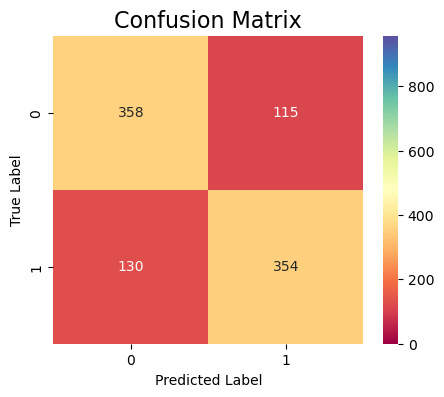

In [171]:
np.random.seed(42)
cv_cm(model, y_train)

In [172]:
#https://stackoverflow.com/questions/73582838/what-is-predict-proba-and-1-after-x-test-in-code
#column index 0 => negative class predictions
#column index 1 => positive class predictions

def set_threshold(chosen_model):
    y_scores = chosen_model.predict_proba(X_test)[:, 1]
    
    precision, recall, thresholds = precision_recall_curve(y_test, y_scores)
    auc_score = auc(recall, precision)
    
    with np.errstate(divide='ignore', invalid='ignore'):
        f1s = 2 * (precision * recall) / (precision + recall)
        f1s[np.isnan(f1s)] = 0  
    
    best_thresh = thresholds[f1s.argmax()]
    print("Best threshold:", best_thresh)
    
    y_pred_reg_opt = (y_scores >= best_thresh).astype(int)
    return y_pred_reg_opt

In [173]:
from sklearn.metrics import RocCurveDisplay, auc
from sklearn.model_selection import cross_validate

def roc_cv(best_model):
    n_splits = 5
    cv = 5
    cv_results = cross_validate(
        best_model, X, y, cv=cv, return_estimator=True, return_indices=True
    )
    
    prop_cycle = plt.rcParams["axes.prop_cycle"]
    colors = prop_cycle.by_key()["color"]
    curve_kwargs_list = [
        dict(alpha=0.3, lw=1, color=colors[fold % len(colors)]) for fold in range(n_splits)
    ]
    names = [f"ROC fold {idx}" for idx in range(n_splits)]
    
    mean_fpr = np.linspace(0, 1, 100)
    interp_tprs = []
    
    _, ax = plt.subplots(figsize=(6, 6))
    viz = RocCurveDisplay.from_cv_results(
        cv_results,
        X,
        y,
        ax=ax,
        name=names,
        curve_kwargs=curve_kwargs_list,
        plot_chance_level=True,
    )
    
    for idx in range(n_splits):
        interp_tpr = np.interp(mean_fpr, viz.fpr[idx], viz.tpr[idx])
        interp_tpr[0] = 0.0
        interp_tprs.append(interp_tpr)
    
    mean_tpr = np.mean(interp_tprs, axis=0)
    mean_tpr[-1] = 1.0
    mean_auc = auc(mean_fpr, mean_tpr)
    std_auc = np.std(viz.roc_auc)
    
    ax.plot(
        mean_fpr,
        mean_tpr,
        color="b",
        label=r"Mean ROC (AUC = %0.2f $\pm$ %0.2f)" % (mean_auc, std_auc),
        lw=2,
        alpha=0.8,
    )
    
    std_tpr = np.std(interp_tprs, axis=0)
    tprs_upper = np.minimum(mean_tpr + std_tpr, 1)
    tprs_lower = np.maximum(mean_tpr - std_tpr, 0)
    ax.fill_between(
        mean_fpr,
        tprs_lower,
        tprs_upper,
        color="grey",
        alpha=0.2,
        label=r"$\pm$ 1 std. dev.",
    )
    
    ax.set(
        xlabel="False Positive Rate",
        ylabel="True Positive Rate"
    )
    ax.legend(loc="lower right")
    plt.show()

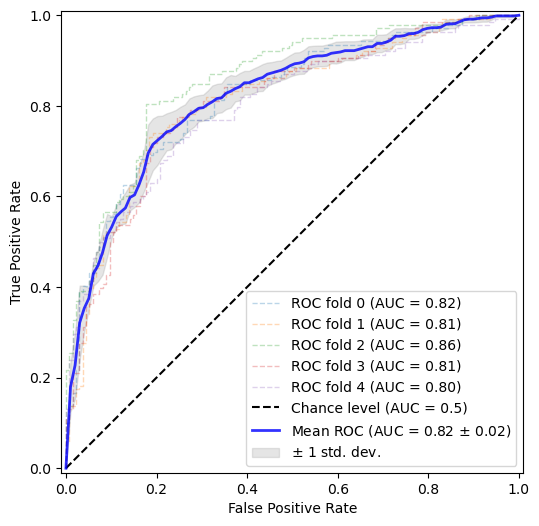

In [174]:
np.random.seed(42)
roc_cv(best_model)

In [175]:
train_sizes = np.linspace(0.4, 1.0, 5)

evals = {"accuracy", "roc_auc", "f1", "precision", "recall"}

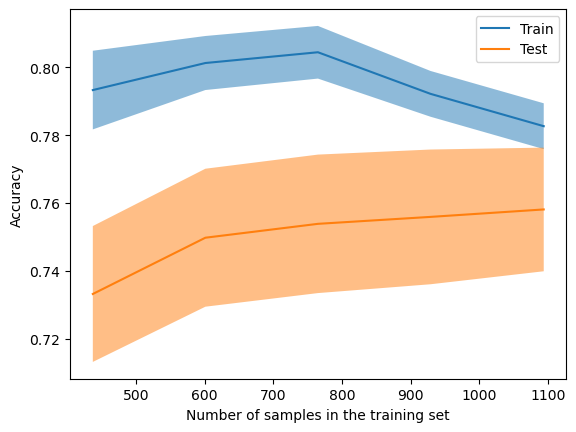

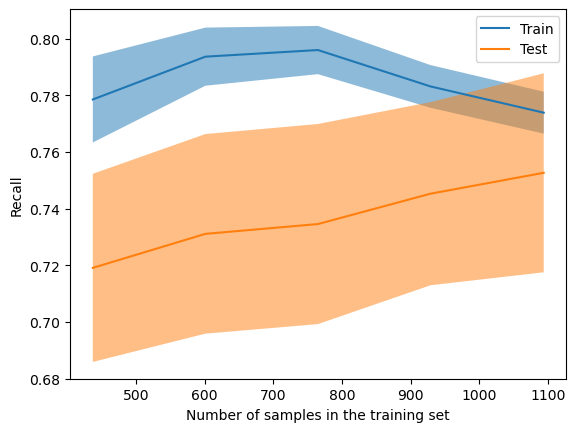

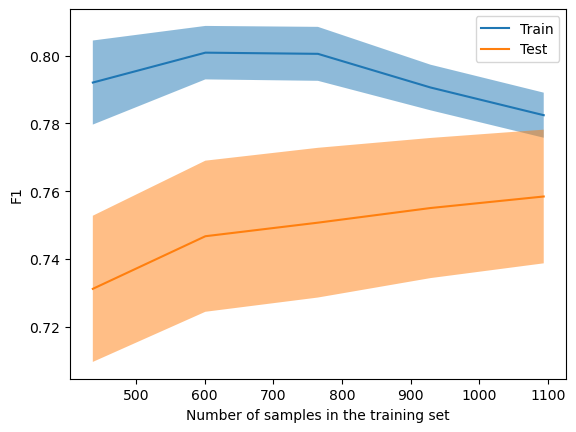

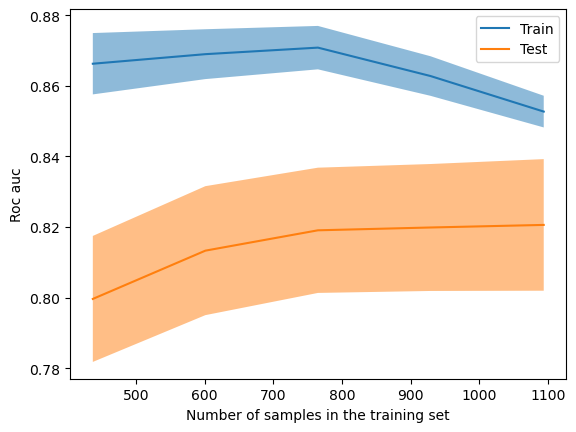

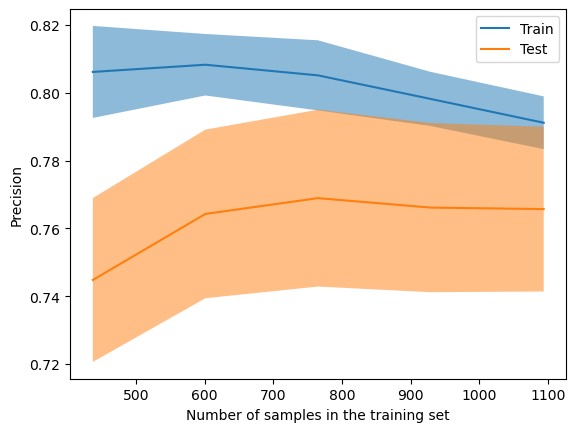

In [176]:
np.random.seed(42)
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_model, X, y, scoring = i, cv = cv, train_sizes = train_sizes, error_score = "raise")

In [177]:
from sklearn.model_selection import cross_val_score

def model_evaluation(estimator):

    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats = 5, random_state=42)
    metrics = {"accuracy", "roc_auc", "f1", "precision", "recall"}
    
    for i in metrics:
        scores = cross_val_score(estimator, X, y, scoring=i, cv=cv)
        
        print("Mean " + i + ":", scores.mean())
        print("Standard deviation:", scores.std())
        print("\n")

In [178]:
np.random.seed(42)
model_evaluation(best_model)

Mean accuracy: 0.7576011336595279
Standard deviation: 0.016951706833772697


Mean recall: 0.7504910853925554
Standard deviation: 0.0332124433696352


Mean f1: 0.7575489444076472
Standard deviation: 0.018338646272300422


Mean roc_auc: 0.8204280615291796
Standard deviation: 0.016174158342180986


Mean precision: 0.7661895576764992
Standard deviation: 0.024614614465429282




In [179]:
import shap

In [180]:
best_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The

In [181]:
best_model = best_model.named_steps['classifier']

In [182]:
fitted_preprocessor = clf_lr.named_steps['preprocessor']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [183]:
explainer = shap.Explainer(best_model, X_train_transformed_df, model_output = 'probability')
shap_values_ohe = explainer(X_train_transformed_df)
shap_values = united_shapley(shap_values_ohe)

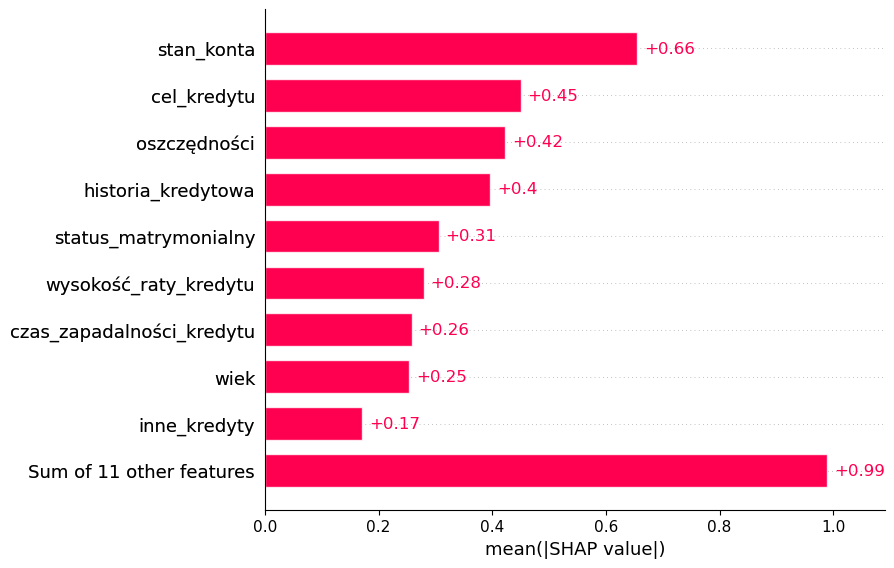

In [184]:
np.random.seed(42)
shap.plots.bar(shap_values)

In [185]:
X_train.iloc[1]

stan_konta                       2
czas_zapadalności_kredytu       30
historia_kredytowa               2
cel_kredytu                      2
wielkość_kredytu              3441
oszczędności                     2
czas_zatrudnienia                3
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               2
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            21
inne_kredyty                     1
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 413, dtype: object

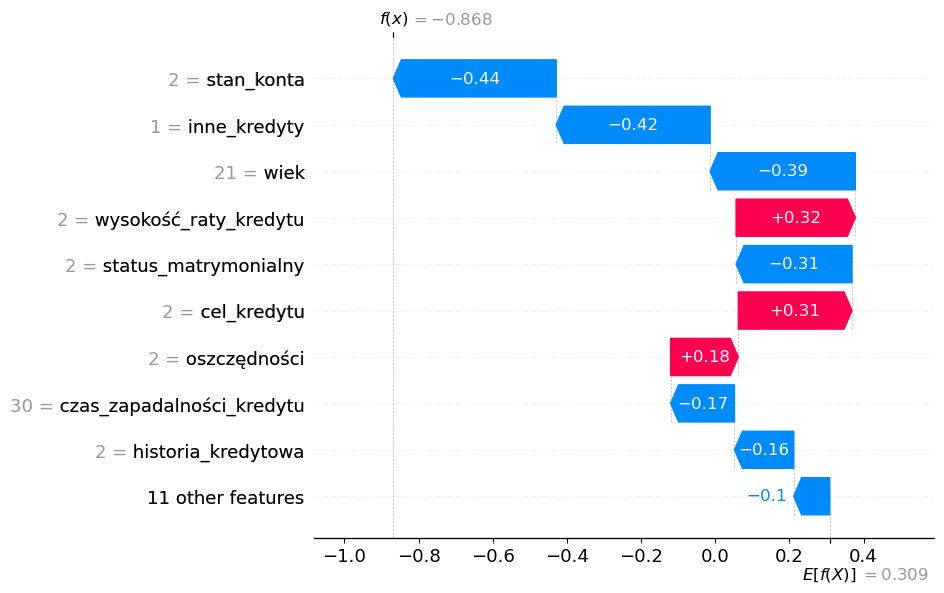

In [186]:
np.random.seed(42)
shap.plots.waterfall(shap_values[1], show=True)

In [187]:
X_train.iloc[150]

stan_konta                       1
czas_zapadalności_kredytu       24
historia_kredytowa               3
cel_kredytu                      3
wielkość_kredytu              1024
oszczędności                     1
czas_zatrudnienia                2
wysokość_raty_kredytu            4
status_matrymonialny             4
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              1
wiek                            48
inne_kredyty                     2
sposób_opłaty_mieszkania         2
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 885, dtype: object

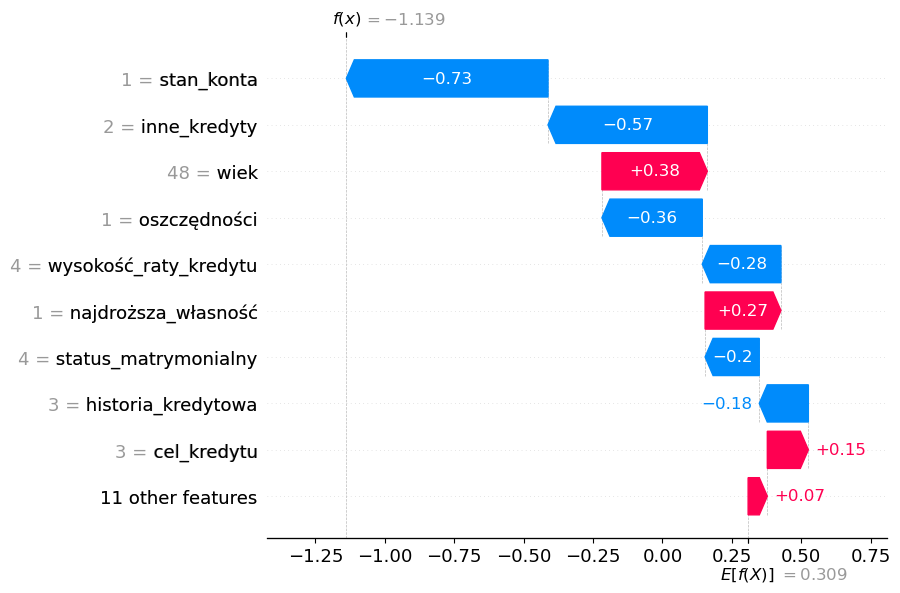

In [188]:
np.random.seed(42)
shap.plots.waterfall(shap_values[150], show=True)

In [189]:
X_train.iloc[250]

stan_konta                       2
czas_zapadalności_kredytu       24
historia_kredytowa               2
cel_kredytu                      1
wielkość_kredytu              6056
oszczędności                     1
czas_zatrudnienia                5
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            32
inne_kredyty                     2
sposób_opłaty_mieszkania         2
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 325, dtype: object

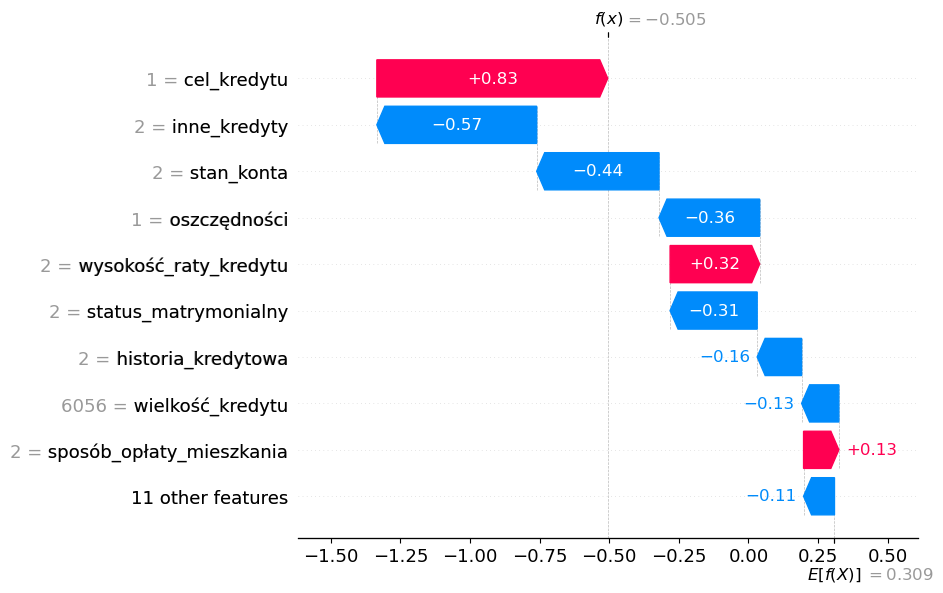

In [190]:
np.random.seed(42)
shap.plots.waterfall(shap_values[250], show=True)

In [191]:
from sklearn.metrics import brier_score_loss

In [192]:
y_scores = best_model.predict_proba(X_test_transformed)[:, 1]

In [193]:
np.random.seed(42)
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.15883805225244993

In [194]:
y_predicted = best_model.predict(X_test_transformed)

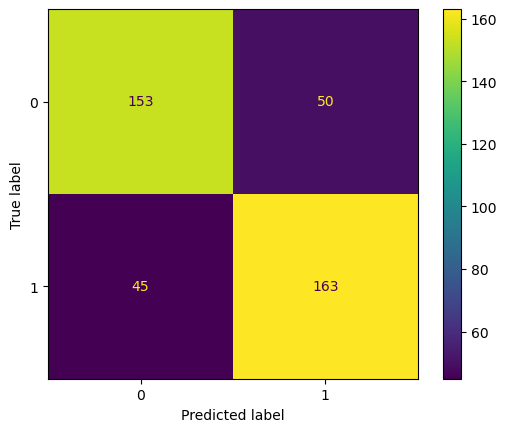

In [195]:
np.random.seed(42)
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

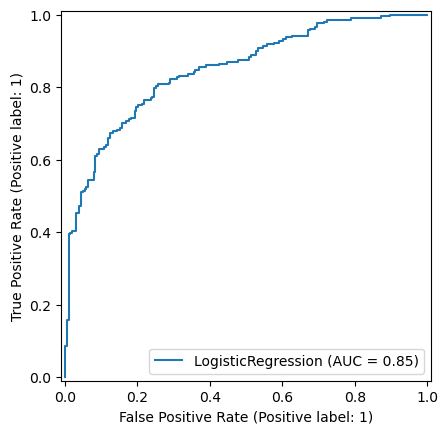

In [196]:
np.random.seed(42)
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_estimator(best_model, X_test_transformed, y_test)

In [197]:
np.random.seed(42)
accuracy_score(y_test, y_predicted)

0.7688564476885644

In [198]:
np.random.seed(42)
recall_score(y_test, y_predicted)

0.7836538461538461

In [199]:
np.random.seed(42)
precision_score(y_test, y_predicted)

0.7652582159624414

In [200]:
from sklearn.metrics import brier_score_loss

In [201]:
from sklearn.svm import LinearSVC

In [202]:
from imblearn.pipeline import Pipeline

In [203]:
np.random.seed(42)
clf_svc = Pipeline(steps = [('preprocessing', transform_data(X_train, num_cols, cat_cols, 'all')),
                            ('classifier', LinearSVC(random_state = 42))])

In [204]:
from scipy.stats import randint, loguniform

param_distributions = {
    'classifier__C': loguniform(0.1, 10),
    'classifier__penalty': ['l1', 'l2'],
    'classifier__max_iter' : randint(8000, 9000)
}

In [205]:
model_svc = RandomizedSearchCV(clf_svc, 
                              param_distributions = param_distributions, 
                              scoring = ['precision', 'recall', 'accuracy', 'f1', 'balanced_accuracy'],
                              n_iter = 10,
                              n_jobs = 1, 
                              cv = cv, 
                              random_state = 42, 
                              refit = 'balanced_accuracy')

In [206]:
model_svc.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__C': <scipy.stats....0022F4B499090>, 'classifier__max_iter': <scipy.stats....0022F4B4991D0>, 'classifier__penalty': ['l1', 'l2']}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['precision', 'recall', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'balanced_accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscros

In [207]:
pd.DataFrame(model_svc.cv_results_)[['rank_test_precision', 'mean_test_precision', 'std_test_precision']].sort_values(by = "rank_test_precision")

,rank_test_precision,mean_test_precision,std_test_precision
3,1,0.756486,0.031576
7,2,0.755877,0.031589
2,3,0.755340,0.031024
8,4,0.754071,0.031758
5,5,0.753504,0.032568
0,6,0.752876,0.031158
9,7,0.752795,0.031608
4,8,0.750020,0.031026
1,9,0.749477,0.030802
6,10,0.749371,0.031592


In [208]:
best_svc = model_svc.best_estimator_

In [209]:
y_pred_best = best_svc.predict(X_test)

In [210]:
y_scores = best_svc.predict(X_test)

accuracy:  0.7438907068062827
recall:  0.734748711340206
precision:  0.7527946278517155


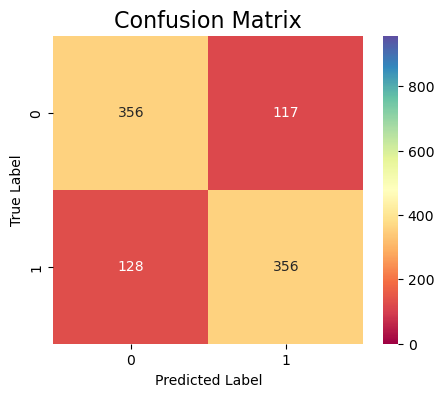

In [211]:
np.random.seed(42)
cv_cm(model_svc, y_train)

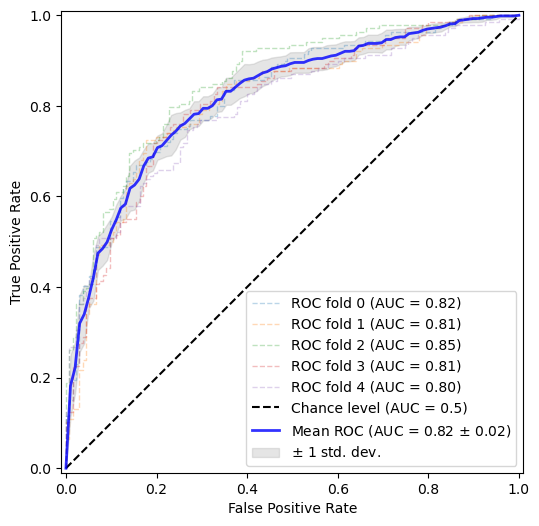

In [212]:
np.random.seed(42)
roc_cv(model_svc)

In [213]:
train_sizes = np.linspace(0.4, 1.0, 5)

evals = {"accuracy", "roc_auc", "f1", "precision", "recall"}

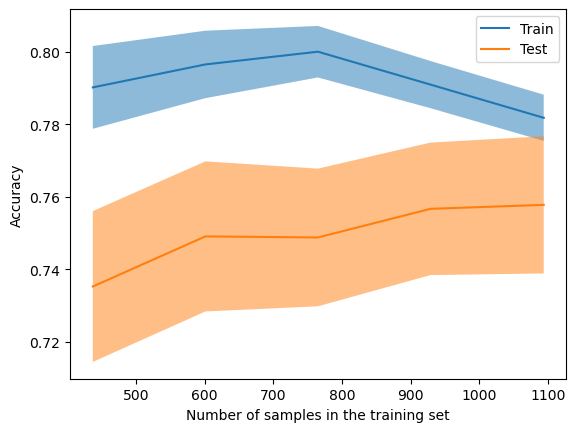

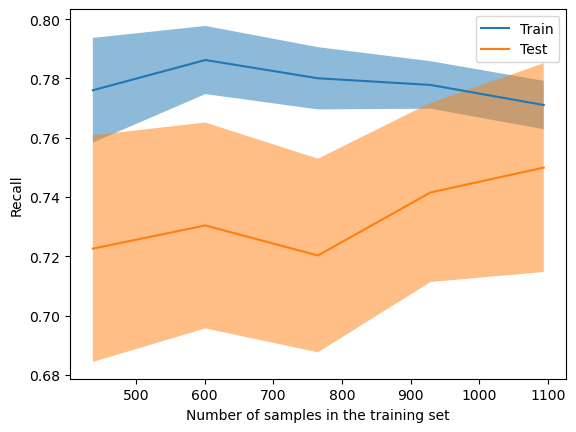

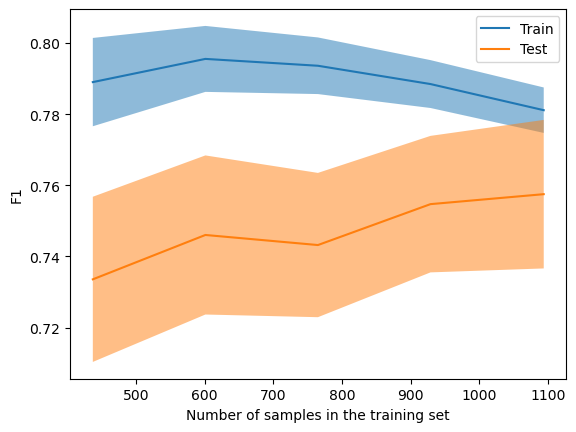

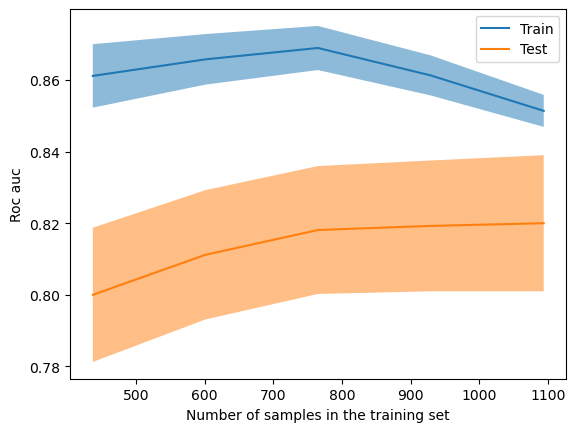

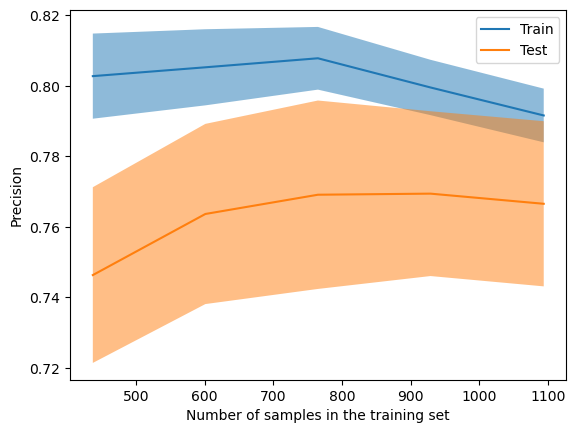

In [214]:
np.random.seed(42)
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_svc, X, y, scoring = i, cv = cv, train_sizes = train_sizes)

In [215]:
np.random.seed(42)
model_evaluation(best_svc)

Mean accuracy: 0.7575904387583221
Standard deviation: 0.01944151713072468


Mean recall: 0.7481680742362632
Standard deviation: 0.03769031499699128


Mean f1: 0.7568269452798703
Standard deviation: 0.02254610480182548


Mean roc_auc: 0.8192374047337861
Standard deviation: 0.016776004283580073


Mean precision: 0.7670121676017496
Standard deviation: 0.02234558108259661




In [216]:
best_svc.fit(X_train, y_train)

,steps,"[('preprocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. Th

In [217]:
best_svc = best_svc.named_steps['classifier']

In [218]:
fitted_preprocessor = clf_svc.named_steps['preprocessing']

X_train_transformed = fitted_preprocessor.fit_transform(X_train)
X_test_transformed = fitted_preprocessor.fit_transform(X_test)

In [219]:
feature_names = fitted_preprocessor.get_feature_names_out()

In [220]:
X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [221]:
svc_explainer = shap.Explainer(best_svc, X_train_transformed_df)
svc_shap_values = svc_explainer(X_train_transformed_df)
svc_shap_values = united_shapley(svc_shap_values)

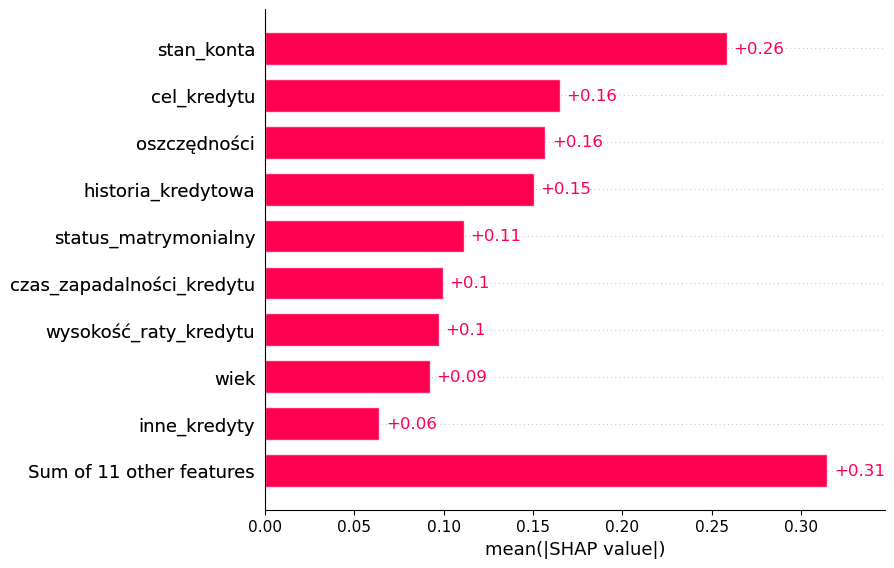

In [222]:
np.random.seed(42)
shap.plots.bar(svc_shap_values)

In [223]:
X_train.iloc[1]

stan_konta                       2
czas_zapadalności_kredytu       30
historia_kredytowa               2
cel_kredytu                      2
wielkość_kredytu              3441
oszczędności                     2
czas_zatrudnienia                3
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               2
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            21
inne_kredyty                     1
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 413, dtype: object

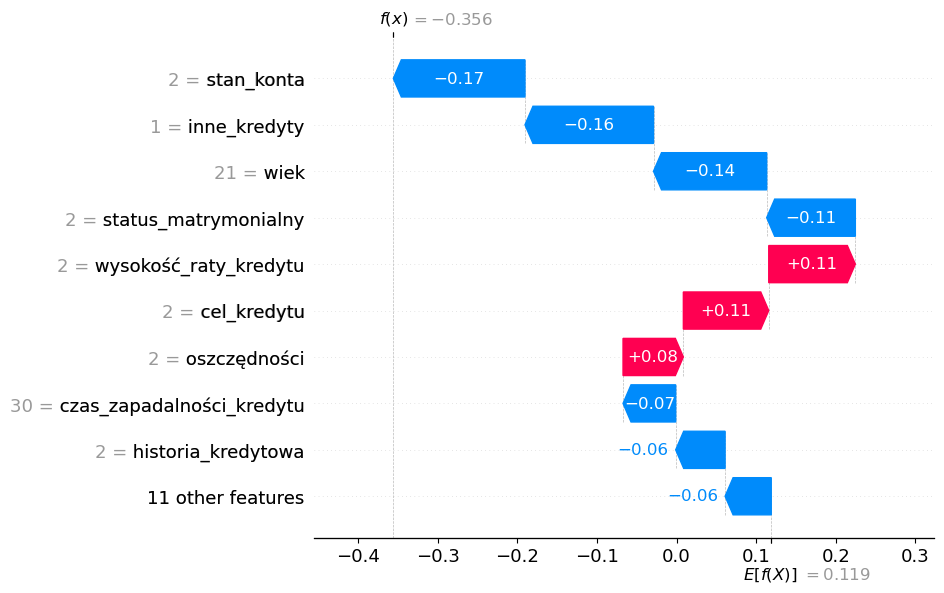

In [224]:
np.random.seed(42)
shap.plots.waterfall(svc_shap_values[1], show=True)

In [225]:
X_train.iloc[150]

stan_konta                       1
czas_zapadalności_kredytu       24
historia_kredytowa               3
cel_kredytu                      3
wielkość_kredytu              1024
oszczędności                     1
czas_zatrudnienia                2
wysokość_raty_kredytu            4
status_matrymonialny             4
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              1
wiek                            48
inne_kredyty                     2
sposób_opłaty_mieszkania         2
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 885, dtype: object

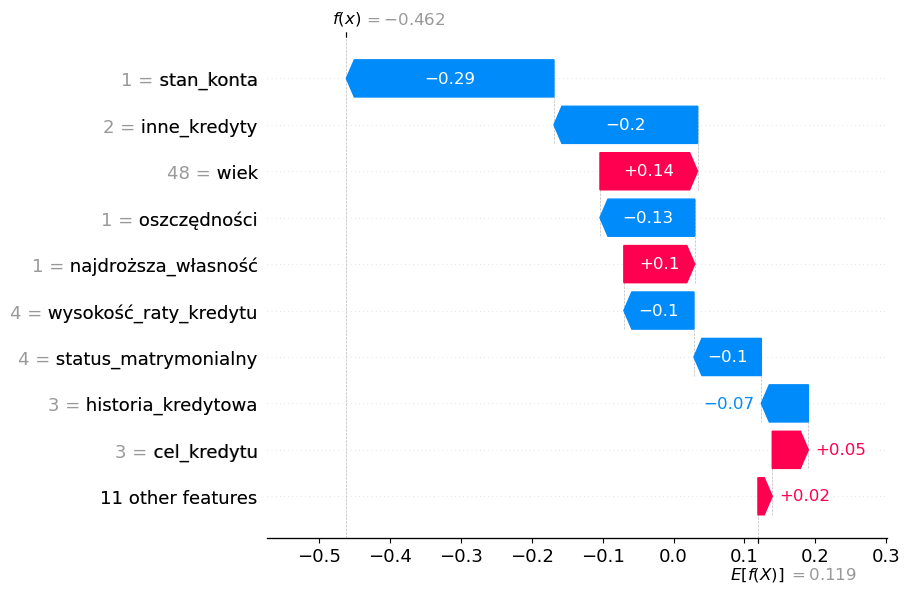

In [226]:
np.random.seed(42)
shap.plots.waterfall(svc_shap_values[150], show=True)

In [227]:
X_train.iloc[250]

stan_konta                       2
czas_zapadalności_kredytu       24
historia_kredytowa               2
cel_kredytu                      1
wielkość_kredytu              6056
oszczędności                     1
czas_zatrudnienia                5
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            32
inne_kredyty                     2
sposób_opłaty_mieszkania         2
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 325, dtype: object

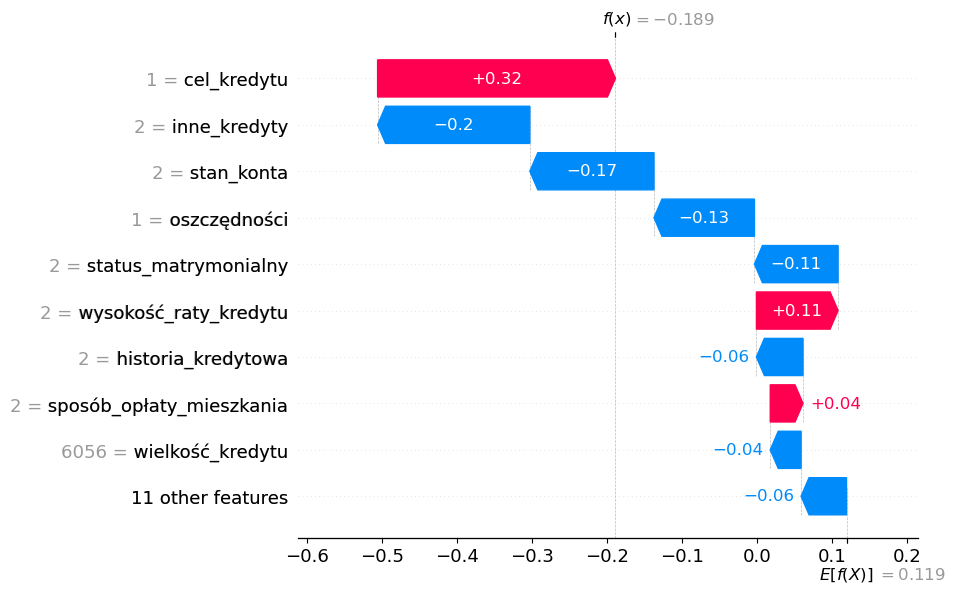

In [228]:
np.random.seed(42)
shap.plots.waterfall(svc_shap_values[250], show=True)

In [229]:
from sklearn.metrics import brier_score_loss

In [230]:
y_scores = best_svc.predict(X_test_transformed)

In [231]:
np.random.seed(42)
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.24087591240875914

In [232]:
y_predicted = best_svc.predict(X_test_transformed)

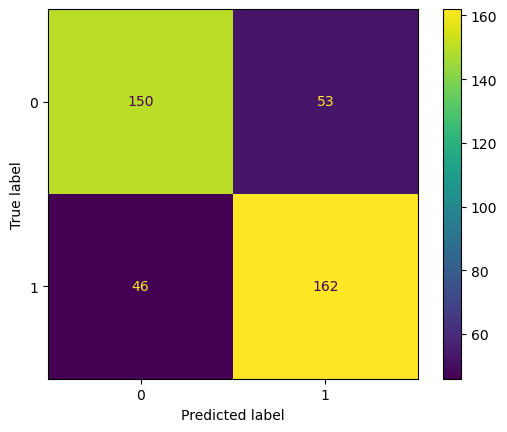

In [233]:
np.random.seed(42)
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

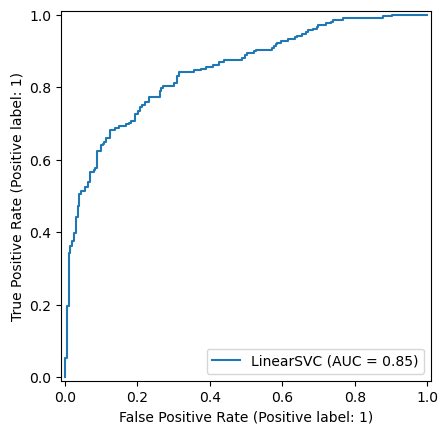

In [234]:
np.random.seed(42)
RocCurveDisplay.from_estimator(best_svc, X_test_transformed, y_test)

In [235]:
np.random.seed(42)
accuracy_score(y_test, y_predicted)

0.7591240875912408

In [236]:
np.random.seed(42)
recall_score(y_test, y_predicted)

0.7788461538461539

In [237]:
np.random.seed(42)
precision_score(y_test, y_predicted)

0.7534883720930232

In [238]:
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.ensemble import RandomForestClassifier

In [239]:
rf = RandomForestClassifier(random_state = 42)

In [240]:
clf_rf = Pipeline(steps = [('preprocessor', transform_data(X_train, num_cols, cat_cols, 'cat')),
    ('classifier', RandomForestClassifier(random_state = 42))])

In [241]:
param_distributions = {
    'classifier__n_estimators': randint(80, 100),
    'classifier__max_depth': randint(2, 3),
    'classifier__min_samples_split': randint(10, 15),
    'classifier__min_samples_leaf': randint(2, 7),
    'classifier__max_features': ['sqrt', 'log2'],
    'classifier__criterion': ['gini', 'entropy']
}

In [242]:
model_rf = RandomizedSearchCV(clf_rf, 
                              param_distributions = param_distributions, 
                              cv = cv, 
                              n_iter = 5, 
                              n_jobs = -1, 
                              scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], 
                              return_train_score = True, 
                              refit = 'balanced_accuracy', 
                              random_state = 42,
                             error_score = 'raise')

In [243]:
model_rf.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__criterion': ['gini', 'entropy'], 'classifier__max_depth': <scipy.stats....0022F47CFE850>, 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': <scipy.stats....0022F48034320>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['recall', 'accuracy', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'balanced_accuracy'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits

In [244]:
best_rf = model_rf.best_estimator_

accuracy:  0.7185073080279232
recall:  0.7146434707903779
precision:  0.7252951626411398


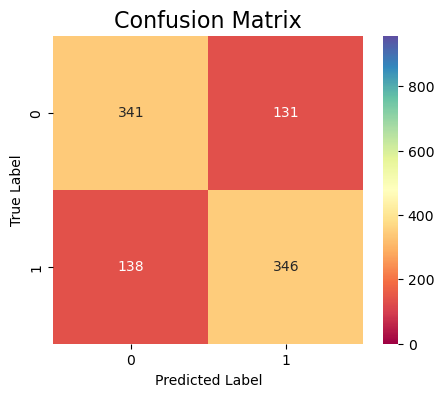

In [245]:
np.random.seed(42)
cv_cm(model_rf, y_train)

In [317]:
np.random.seed(42)
roc_cv(model_rf)

KeyboardInterrupt: 

KeyboardInterrupt: 

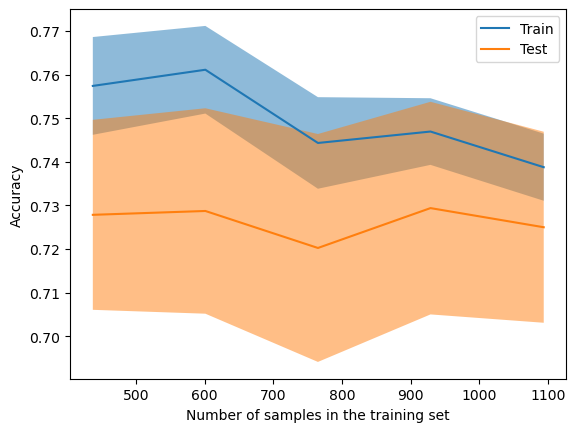

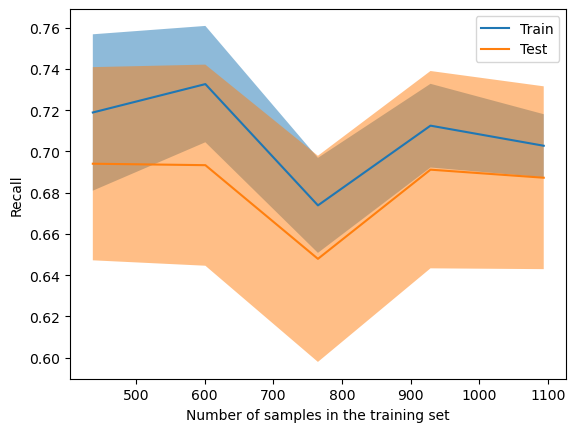

In [320]:
for i in evals:
     display = LearningCurveDisplay.from_estimator(best_rf, X, y, scoring = i, cv = cv, train_sizes = train_sizes, n_jobs = -1)

In [252]:
np.random.seed(42)
model_evaluation(best_rf)

Mean accuracy: 0.7318708055934333
Standard deviation: 0.022154475586080535


Mean recall: 0.7244270670420185
Standard deviation: 0.044902412783417694


Mean f1: 0.7313321429376507
Standard deviation: 0.02640015333811339


Mean roc_auc: 0.8037861726532387
Standard deviation: 0.021220041696197255


Mean precision: 0.7401883488355628
Standard deviation: 0.024572873984771634




In [253]:
best_rf.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The

In [254]:
best_rf = best_rf.named_steps['classifier']

In [255]:
fitted_preprocessor = clf_rf.named_steps['preprocessor']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [256]:
rf_explainer = shap.TreeExplainer(best_rf, X_train_transformed_df, model_output = 'probability')
rf_shap_values = rf_explainer(X_train_transformed_df)
rf_shap_values = united_shapley(rf_shap_values)

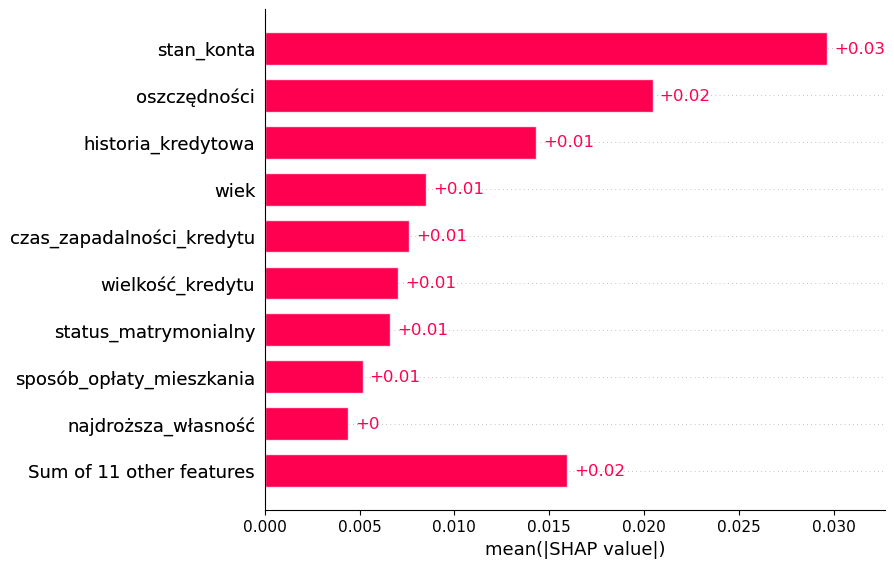

In [257]:
np.random.seed(42)
shap.plots.bar(rf_shap_values)

In [258]:
X_train.iloc[1]

stan_konta                       2
czas_zapadalności_kredytu       30
historia_kredytowa               2
cel_kredytu                      2
wielkość_kredytu              3441
oszczędności                     2
czas_zatrudnienia                3
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               2
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            21
inne_kredyty                     1
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 413, dtype: object

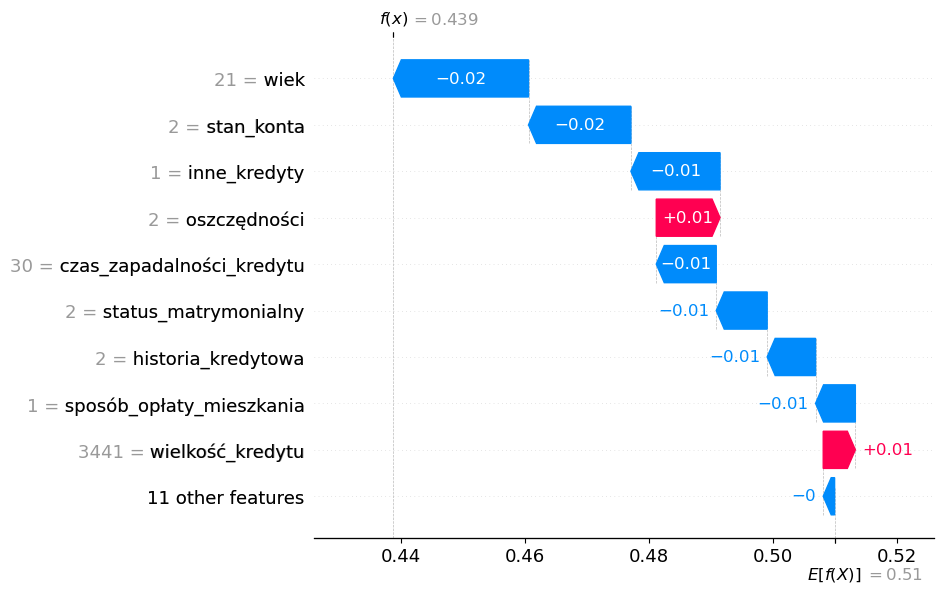

In [259]:
np.random.seed(42)
shap.plots.waterfall(rf_shap_values[1], max_display = 10, show=True)

In [260]:
X_train.iloc[150]

stan_konta                       1
czas_zapadalności_kredytu       24
historia_kredytowa               3
cel_kredytu                      3
wielkość_kredytu              1024
oszczędności                     1
czas_zatrudnienia                2
wysokość_raty_kredytu            4
status_matrymonialny             4
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              1
wiek                            48
inne_kredyty                     2
sposób_opłaty_mieszkania         2
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 885, dtype: object

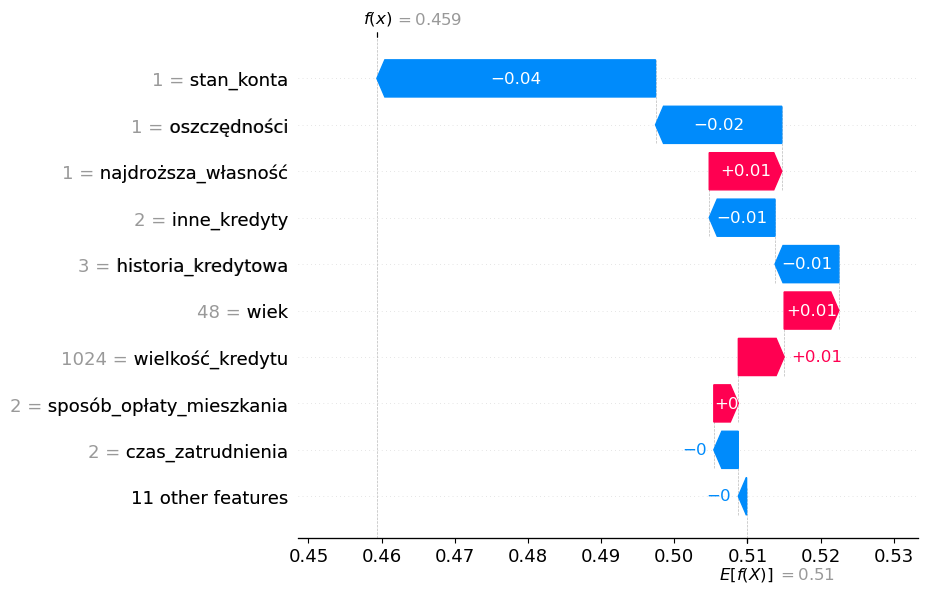

In [261]:
np.random.seed(42)
shap.plots.waterfall(rf_shap_values[150], max_display = 10, show=True)

In [262]:
X_train.iloc[250]

stan_konta                       2
czas_zapadalności_kredytu       24
historia_kredytowa               2
cel_kredytu                      1
wielkość_kredytu              6056
oszczędności                     1
czas_zatrudnienia                5
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            32
inne_kredyty                     2
sposób_opłaty_mieszkania         2
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 325, dtype: object

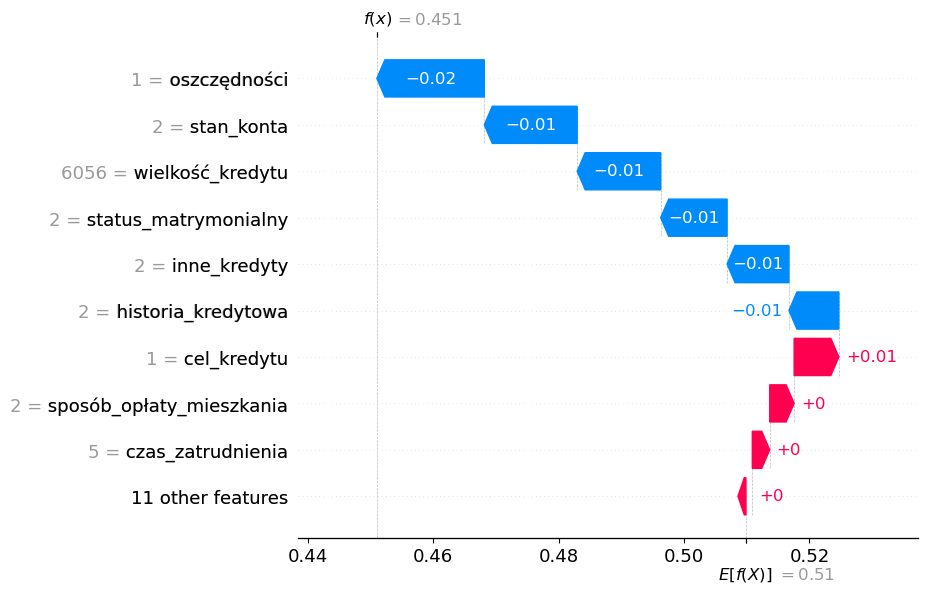

In [263]:
np.random.seed(42)
shap.plots.waterfall(rf_shap_values[250], max_display = 10, show=True)

In [264]:
from sklearn.metrics import brier_score_loss

In [265]:
y_scores = best_rf.predict_proba(X_test_transformed)[:, 1]

In [266]:
np.random.seed(42)
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.21873889291946116

In [267]:
y_predicted = best_rf.predict(X_test_transformed)

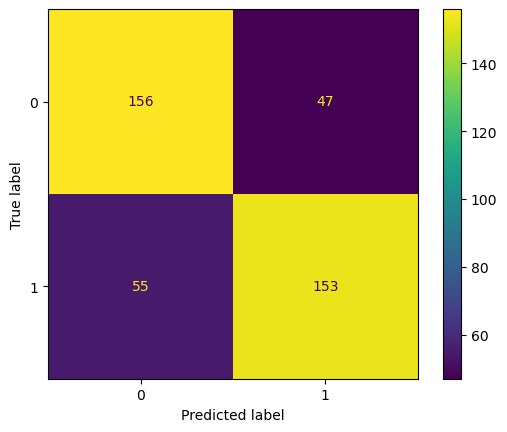

In [268]:
np.random.seed(42)
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

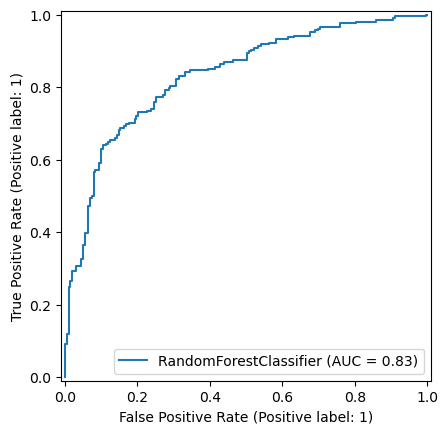

In [269]:
np.random.seed(42)
RocCurveDisplay.from_estimator(best_rf, X_test_transformed, y_test)

In [270]:
np.random.seed(42)
accuracy_score(y_test, y_predicted)

0.7518248175182481

In [271]:
np.random.seed(42)
recall_score(y_test, y_predicted)

0.7355769230769231

In [272]:
np.random.seed(42)
precision_score(y_test, y_predicted)

0.765

In [273]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import PowerTransformer
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

In [308]:
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC

clf_xgb = Pipeline(steps = [('preprocessing', transform_data(X_train, num_cols, cat_cols, 'cat')),
                            ('classifier', XGBClassifier(random_state = 42))])

In [309]:
param_distribution = {
    'classifier__max_depth': [2, 3], 
    'classifier__min_child_weight': randint(10, 20), 
    'classifier__lambda': randint(1, 10), 
    'classifier__alpha': randint(1, 5),
    'classifier__learning_rate': loguniform(0.01, 1),
    'classifier__n_estimators': randint(400, 600),
    'classifier__subsample': loguniform(0.5, 0.6),
    'classifier__colsample_bytree': loguniform(0.5, 0.6),
    'classifier__gamma': randint(2, 4)
}

In [310]:
model_xgb = RandomizedSearchCV(clf_xgb, param_distributions = param_distribution, n_iter = 10, scoring = ['recall', 'accuracy', 'f1_weighted', 'neg_brier_score', 'balanced_accuracy', 'precision'], refit = 'f1_weighted', n_jobs = -1, cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42), random_state = 42, error_score = 'raise')

In [311]:
model_xgb.fit(X_train, y_train)

,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__alpha': <scipy.stats....0022F4697AC80>, 'classifier__colsample_bytree': <scipy.stats....0022F50FB2150>, 'classifier__gamma': <scipy.stats....0022F4697B5B0>, 'classifier__lambda': <scipy.stats....0022F4697AB30>, ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.","['recall', 'accuracy', ...]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",'f1_weighted'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so th

In [312]:
best_xgb = model_xgb.best_estimator_

In [313]:
y_scores = best_xgb.predict_proba(X_test)[:, 1]

accuracy:  0.7273342059336824
recall:  0.7309063573883162
precision:  0.7314982341155375


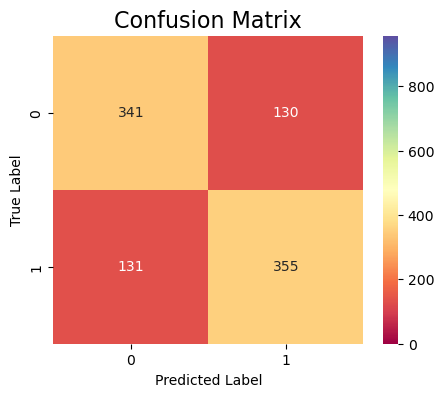

In [314]:
np.random.seed(42)
cv_cm(model_xgb, y_train)

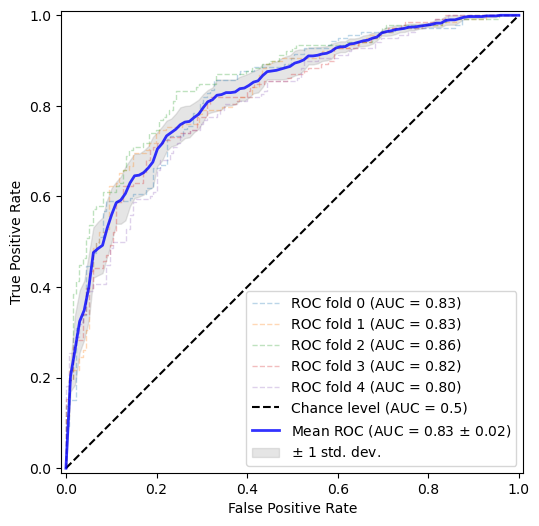

In [315]:
np.random.seed(42)
roc_cv(model_xgb)

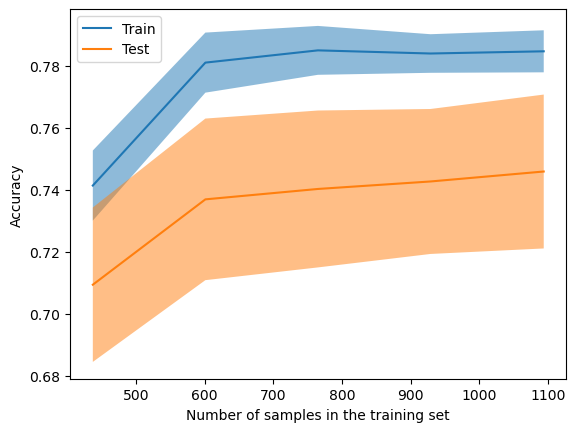

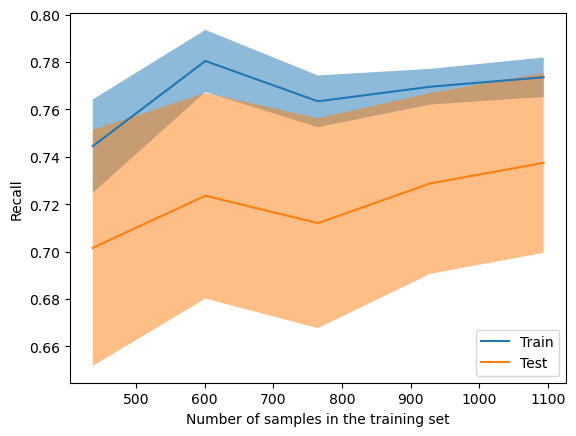

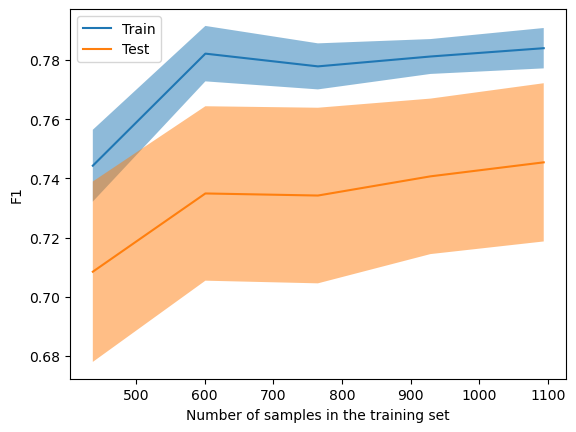

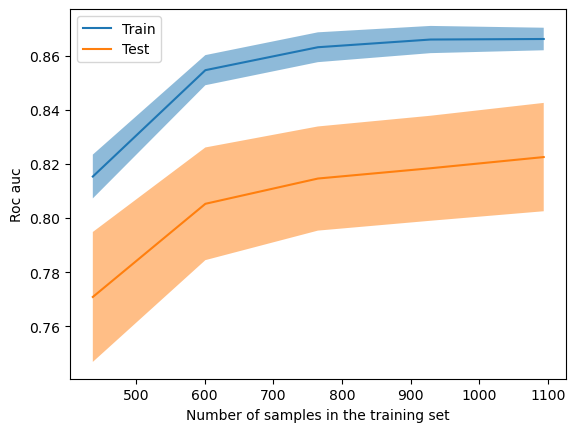

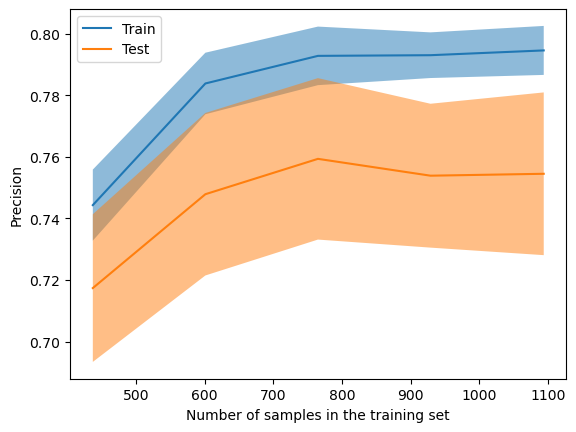

In [316]:
for i in evals:
    display = LearningCurveDisplay.from_estimator(best_xgb, X, y, scoring = i, cv = cv, train_sizes = train_sizes, n_jobs = -1)

In [282]:
np.random.seed(42)
model_evaluation(best_xgb)

Mean accuracy: 0.7454640250260688
Standard deviation: 0.02471756587246713


Mean recall: 0.7354499009488061
Standard deviation: 0.041386009651186925


Mean f1: 0.7444737643565695
Standard deviation: 0.027098414131246928


Mean roc_auc: 0.8221300646325793
Standard deviation: 0.019701298307967335


Mean precision: 0.755081632287134
Standard deviation: 0.026675148816630814




In [283]:
best_xgb = best_xgb.named_steps['classifier']

In [284]:
fitted_preprocessor = clf_xgb.named_steps['preprocessing']

X_train_transformed = fitted_preprocessor.transform(X_train)
X_test_transformed = fitted_preprocessor.transform(X_test)

In [285]:
feature_names = fitted_preprocessor.get_feature_names_out()

X_train_transformed_df = pd.DataFrame(X_train_transformed, columns = feature_names)
X_test_transformed_df = pd.DataFrame(X_test_transformed, columns = feature_names)

In [286]:
xgb_explainer = shap.TreeExplainer(best_xgb, X_train_transformed_df, model_output = 'probability')

In [287]:
xgb_shap_values_ohe = xgb_explainer(X_train_transformed_df)

In [288]:
xgb_shap_values_ohe = united_shapley(xgb_shap_values_ohe)

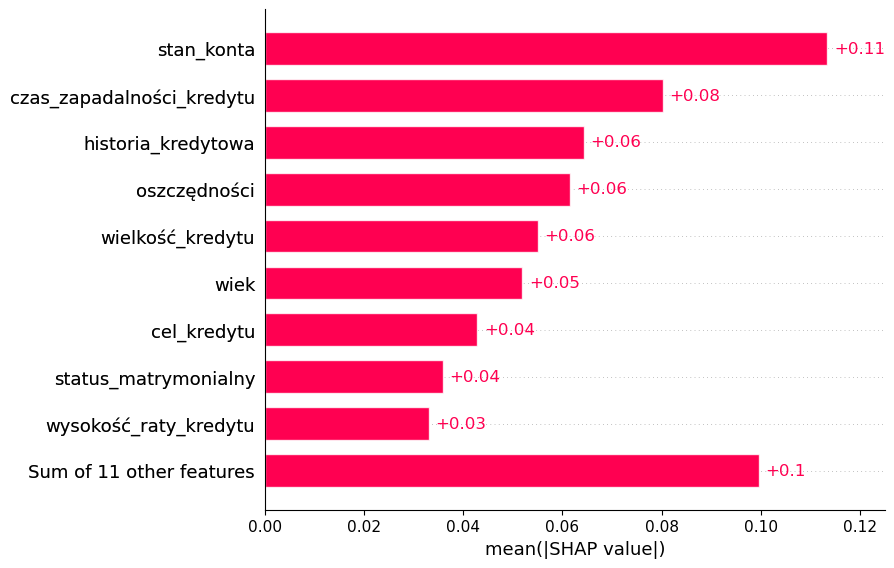

In [289]:
np.random.seed(42)
shap.plots.bar(xgb_shap_values_ohe)

In [290]:
X_train.iloc[1]

stan_konta                       2
czas_zapadalności_kredytu       30
historia_kredytowa               2
cel_kredytu                      2
wielkość_kredytu              3441
oszczędności                     2
czas_zatrudnienia                3
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               2
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            21
inne_kredyty                     1
sposób_opłaty_mieszkania         1
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 413, dtype: object

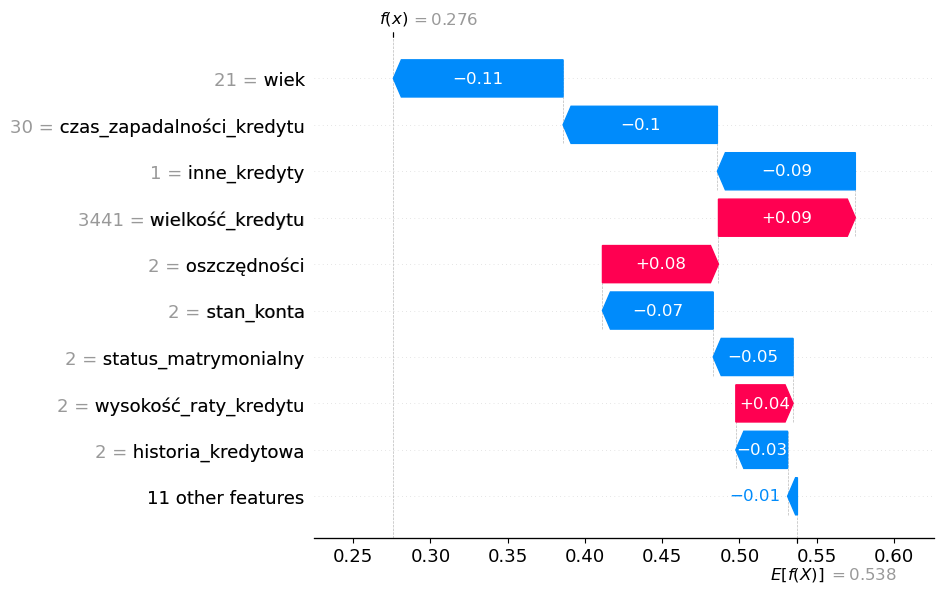

In [291]:
np.random.seed(42)
shap.plots.waterfall(xgb_shap_values_ohe[1], max_display = 10, show=True)

In [292]:
X_train.iloc[150]

stan_konta                       1
czas_zapadalności_kredytu       24
historia_kredytowa               3
cel_kredytu                      3
wielkość_kredytu              1024
oszczędności                     1
czas_zatrudnienia                2
wysokość_raty_kredytu            4
status_matrymonialny             4
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              1
wiek                            48
inne_kredyty                     2
sposób_opłaty_mieszkania         2
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 885, dtype: object

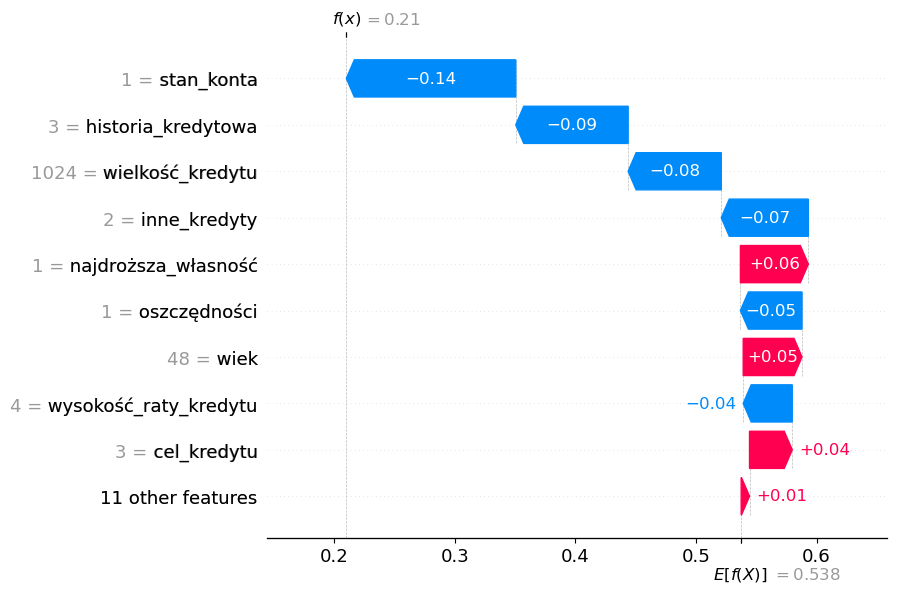

In [293]:
np.random.seed(42)
shap.plots.waterfall(xgb_shap_values_ohe[150], max_display = 10, show=True)

In [294]:
X_train.iloc[250]

stan_konta                       2
czas_zapadalności_kredytu       24
historia_kredytowa               2
cel_kredytu                      1
wielkość_kredytu              6056
oszczędności                     1
czas_zatrudnienia                5
wysokość_raty_kredytu            2
status_matrymonialny             2
inni_kredytobiorcy               1
miejsce_zamieszkania             4
najdroższa_własność              3
wiek                            32
inne_kredyty                     2
sposób_opłaty_mieszkania         2
liczba_kredytów_w_historii       1
praca                            3
liczba_osób_na_utrzymaniu        2
telefon                          1
cudzoziemiec                     2
Name: 325, dtype: object

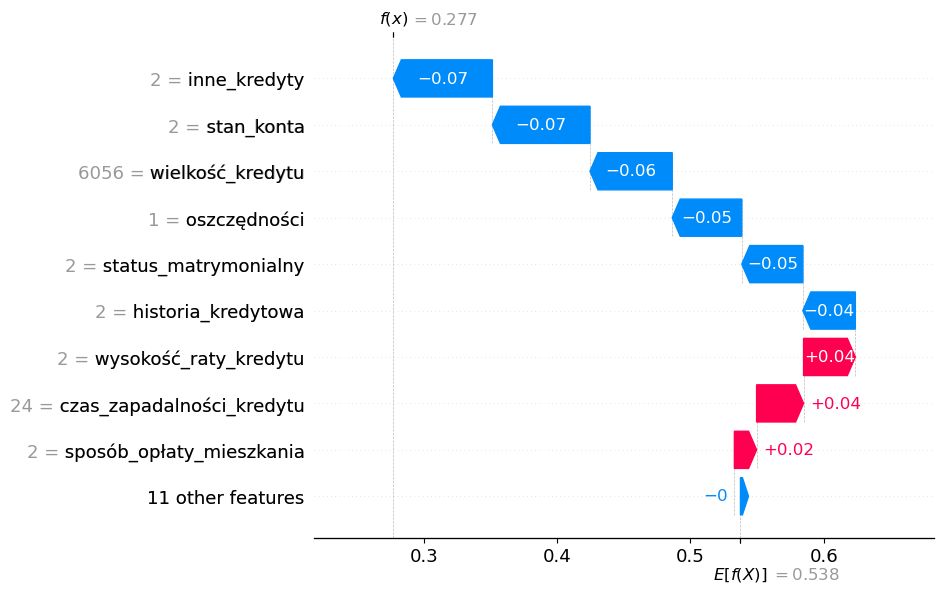

In [295]:
np.random.seed(42)
shap.plots.waterfall(xgb_shap_values_ohe[250], max_display = 10, show=True)

In [296]:
np.random.seed(42)
brier_score_loss(y_test, y_scores, pos_label = 1, scale_by_half = True)

0.15960446000099182

In [297]:
y_predicted = best_xgb.predict(X_test_transformed)

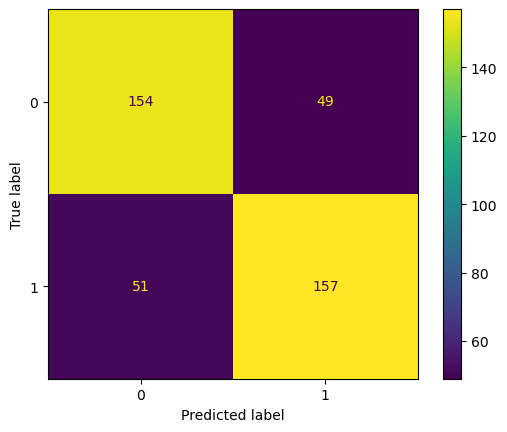

In [298]:
np.random.seed(42)
from sklearn.metrics import confusion_matrix

ConfusionMatrixDisplay(confusion_matrix(y_test, y_predicted)).plot()

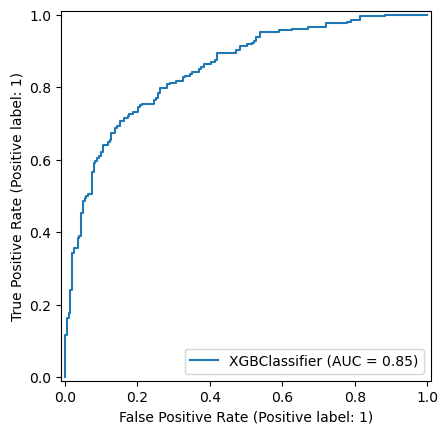

In [299]:
np.random.seed(42)
RocCurveDisplay.from_estimator(best_xgb, X_test_transformed, y_test)

In [300]:
np.random.seed(42)
accuracy_score(y_test, y_predicted)

0.7566909975669099

In [301]:
np.random.seed(42)
recall_score(y_test, y_predicted)

0.7548076923076923

In [302]:
np.random.seed(42)
precision_score(y_test, y_predicted)

0.7621359223300971